In [81]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.circuit.library import RXGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.primitives import StatevectorEstimator

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm

# generate pop-up plot
# from pytplot import get_data
# %matplotlib tk

import logging
import itertools

In [4]:
# suppress the long comment for running generate_preset_pass_manager(optimization_level=1)
qiskit_logger = logging.getLogger('qiskit')
qiskit_logger.setLevel(logging.WARNING)

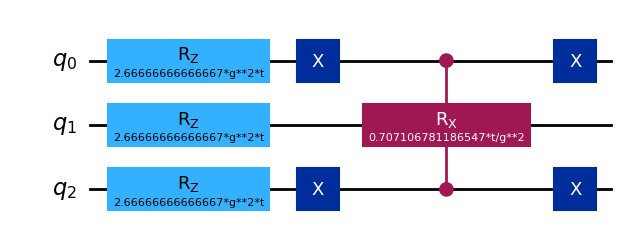

In [6]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

In [10]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ", "IXI", "XXI", "IXX", "XIX", "III"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [11]:
def plot_measurement_loop_one_observable(n, N, observable, t=1.0):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        SparsePauliOp(observable).apply_layout(isa_circuit.layout)
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = N
    return labels, values

In [19]:
def exp_val_given_T(T=1.0, N=40, observable="ZZI", n=3):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = T / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, observable, t)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    ax1.plot(N_s, exp_vals, "o-")
    ax1.set_xlabel("N")
    ax1.set_ylabel(f"{observable} Expectation Value")
    ax1.set_xticks(np.arange(1, N+1, 1))
    ax1.set_title(f"Expectation vs N (top axis: t = 1/N)")
    ax1.grid(True)

    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(N_s)
    ax2.set_xticklabels(f"{t:.3f}" for t in t_s)
    ax2.tick_params(axis="x", labelrotation=45, pad=10)
    ax2.set_xlabel("t = 1 / N")

    plt.tight_layout()
    plt.show()

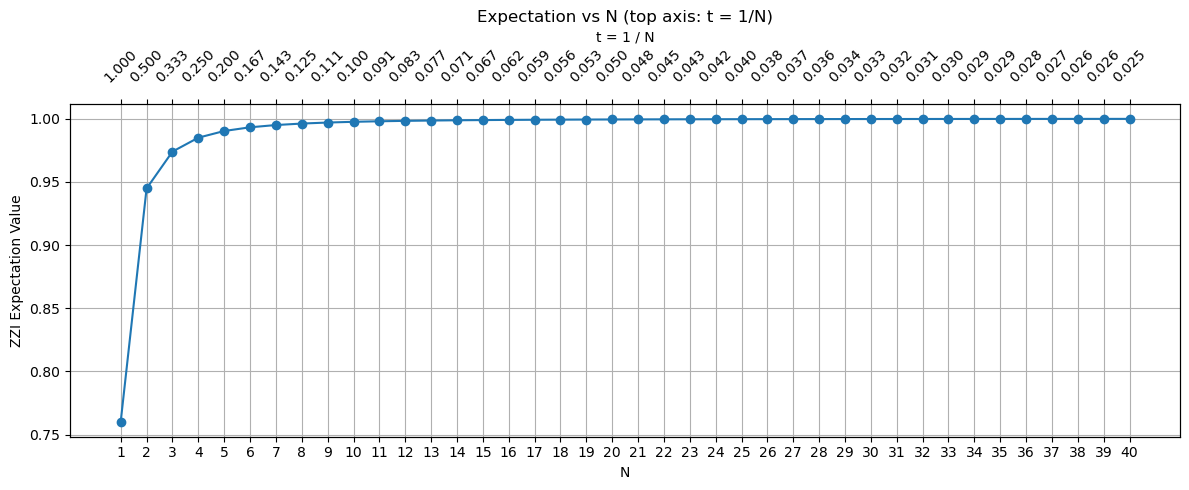

In [21]:
exp_val_given_T()

In [23]:
def plot_measurement_loop_one_observable_with_K(n, N, observable, t, K):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        SparsePauliOp(observable).apply_layout(isa_circuit.layout)
    ]

    g = 1.0/K
    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [g, t])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = N
    return labels, values

In [35]:
def exp_val_given_T_with_K(T=1.0, N=40, observable="ZZI", n=3, K=1.0):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = T / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable_with_K(n, N, observable, t, K)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(111)
    ax2 = ax1.twiny()

    ax1.plot(N_s, exp_vals, "o-")
    ax1.set_xlabel("N")
    ax1.set_ylabel(f"{observable} Expectation Value")
    ax1.set_xticks(np.arange(1, N+1, 1))
    # ax1.set_title(f"Expectation vs N (top axis: t = 1/N)")
    ax1.grid(True)

    ax2.set_xlim(ax1.get_xlim())
    ax2.set_xticks(N_s)
    ax2.set_xticklabels(f"{t:.3f}" for t in t_s)
    ax2.tick_params(axis="x", labelrotation=45, pad=10)
    ax2.set_xlabel("t = 1 / N")

    plt.title(f"Expectation value for {observable} with T={int(T)}, N={N}, K={int(K)}, g={1/K} for a {n} qubit system")
    plt.tight_layout()
    # plt.savefig("check_plot.png")
    fig.subplots_adjust(top=0.85)
    plt.show()

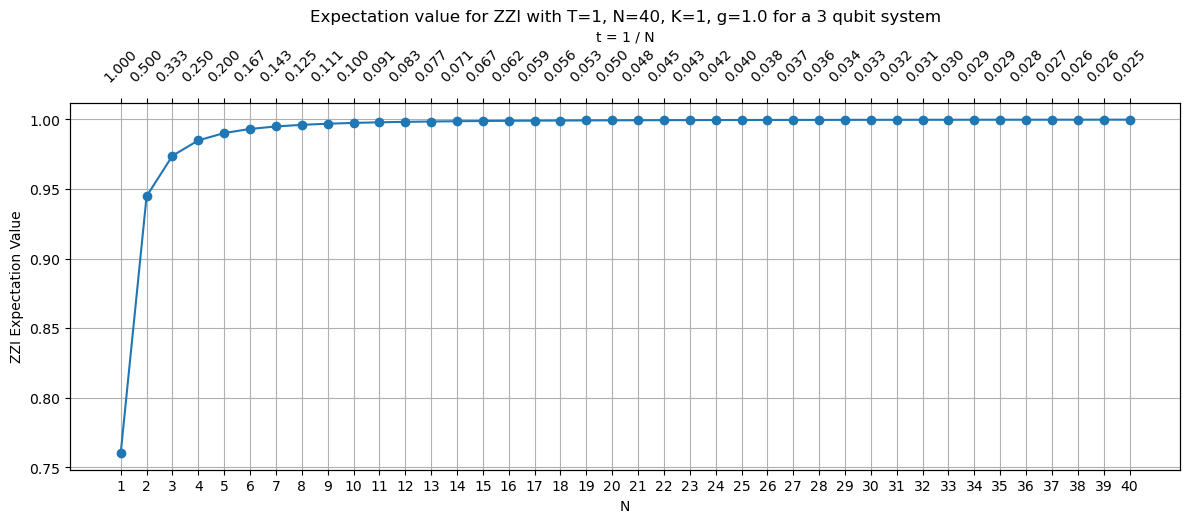

In [37]:
exp_val_given_T_with_K()

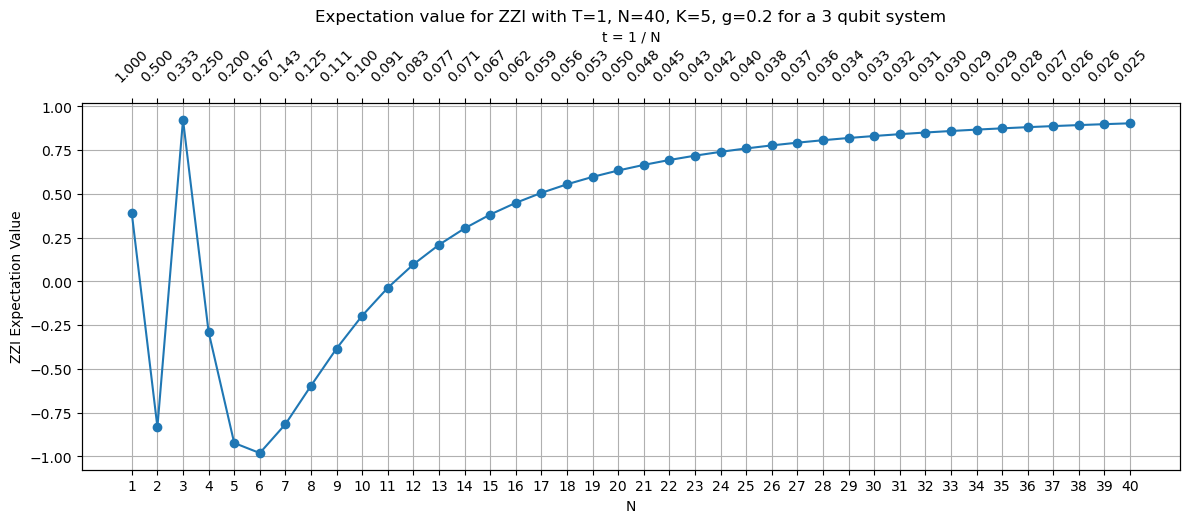

In [39]:
exp_val_given_T_with_K(K=5.0)

In [49]:
# without dual x-axis
def exp_val_given_T_with_K_one_axis(T=1.0, N=40, observable="ZZI", n=3, K=1.0):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = T / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable_with_K(n, N, observable, t, K)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    plt.plot(N_s, exp_vals, "o-")
    plt.xlabel("N")
    plt.ylabel(f"{observable} Expectation Value")
    plt.title(f"Expectation value for {observable} with T={int(T)}, N={N}, K={int(K)} for a {n} qubit system", y=1.02)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

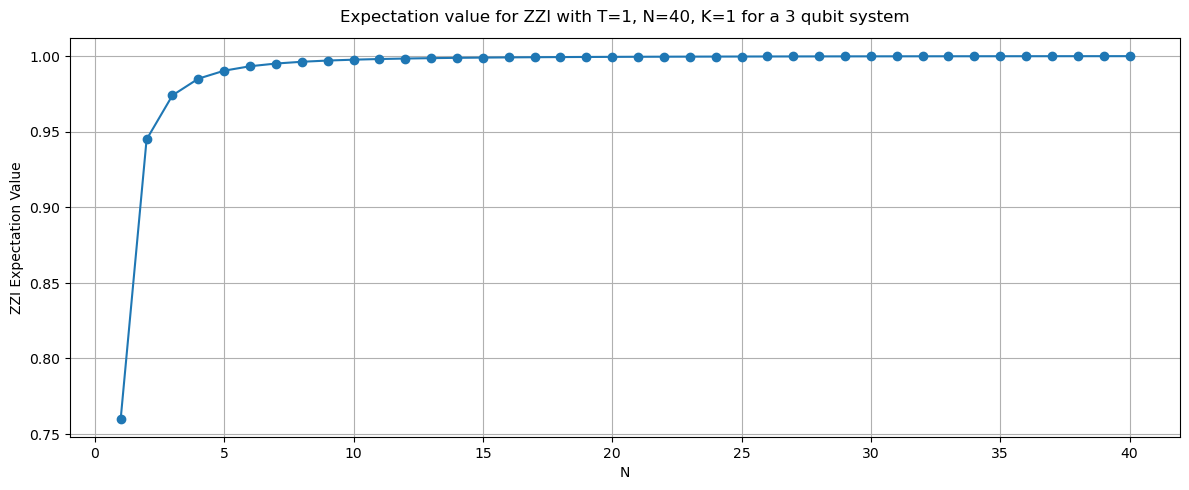

In [51]:
exp_val_given_T_with_K_one_axis()

In [53]:
# arguments: T = total time (t * N)
# N = max time steps, from N will range from 1 to given N
# t = time step size (not an argument)
# K range = max K, g = 1/K
def exp_val_over_K_range(T=1.0, N=40, observable="ZZI", n=3, K_range=5.0):
    N_s = np.arange(1, N+1, 1)
    t_s = T / N_s
    K_vals = np.arange(1.0, K_range, 1.0)

    fig = plt.figure(figsize=(12, 5))

    for K in K_vals:
        exp_vals = []
        for t, N_val in zip(t_s, N_s):
            exp_val = plot_measurement_loop_one_observable_with_K(n, N_val, observable, t, K)[1][0]
            exp_vals.append(exp_val)
        plt.plot(N_s, exp_vals, marker="o", label=f"K = {K}")

    plt.xlabel("N")
    plt.ylabel(f"{observable} Expectation Value")
    plt.title(f"Expectation value for {observable} with T={int(T)}, N={N} over K = 1 to {int(K_range)} for a {n} qubit system", y=1.02)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

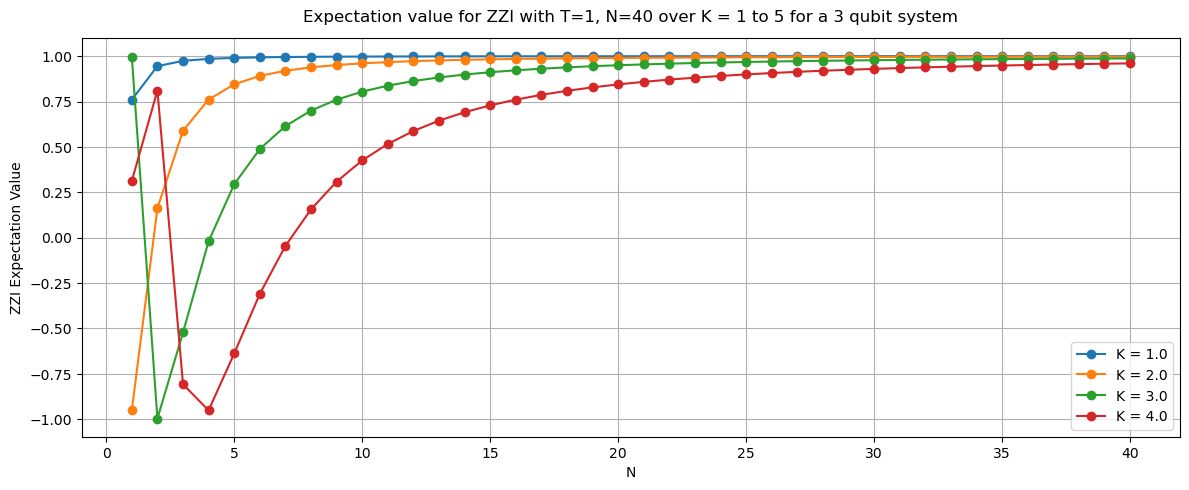

In [57]:
exp_val_over_K_range()

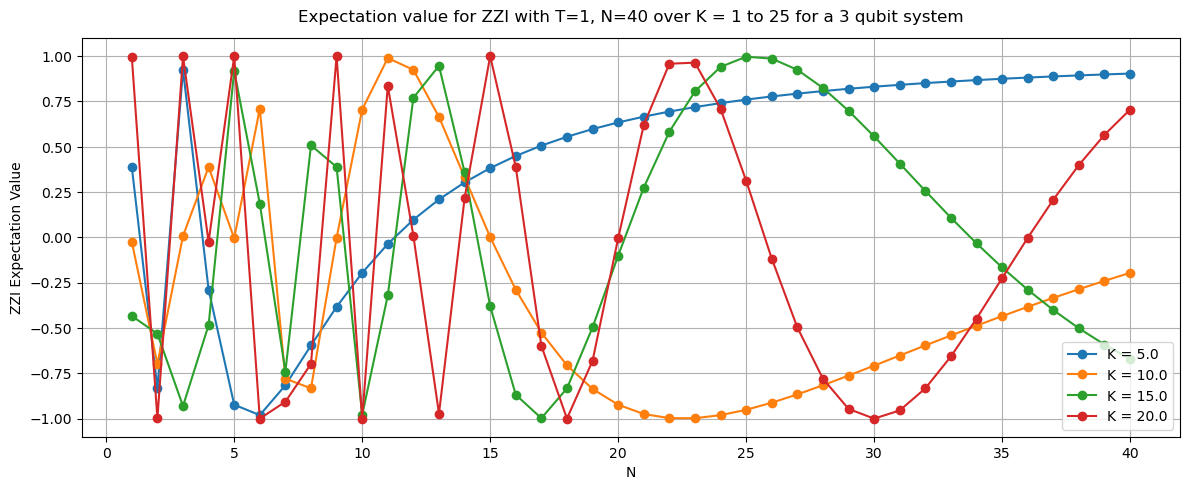

In [59]:
T=1.0
N=40
observable="ZZI"
n=3
K_range=25.0

N_s = np.arange(1, N+1, 1)
t_s = T / N_s
K_vals = np.arange(5.0, K_range, 5.0)

fig = plt.figure(figsize=(12, 5))

for K in K_vals:
    exp_vals = []
    for t, N_val in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable_with_K(n, N_val, observable, t, K)[1][0]
        exp_vals.append(exp_val)
    plt.plot(N_s, exp_vals, marker="o", label=f"K = {K}")

plt.xlabel("N")
plt.ylabel(f"{observable} Expectation Value")
plt.title(f"Expectation value for {observable} with T={int(T)}, N={N} over K = 1 to {int(K_range)} for a {n} qubit system", y=1.02)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

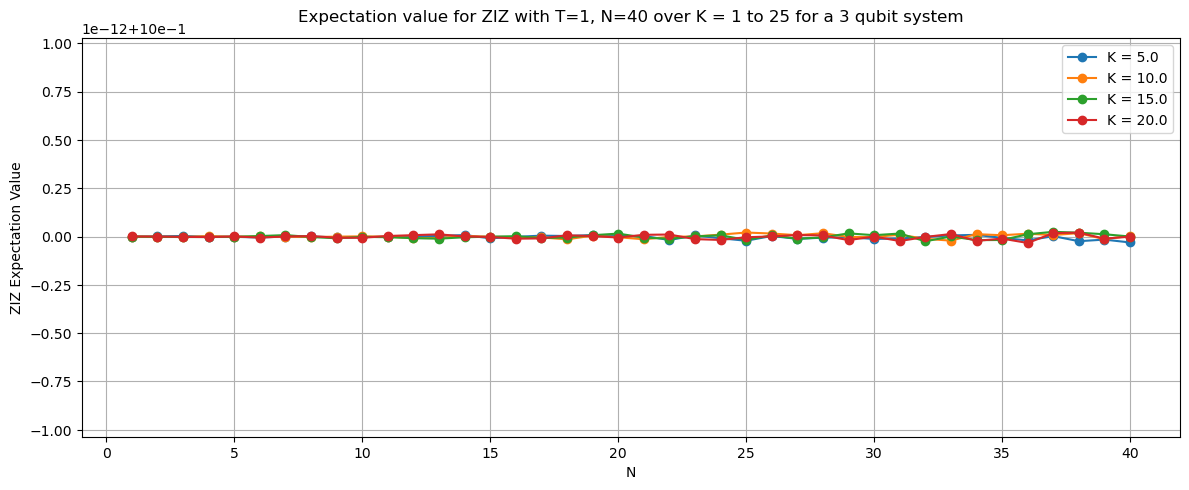

In [117]:
T=1.0
N=40
observable="ZIZ"
n=3
K_range=25.0

N_s = np.arange(1, N+1, 1)
t_s = T / N_s
K_vals = np.arange(5.0, K_range, 5.0)

fig = plt.figure(figsize=(12, 5))

for K in K_vals:
    exp_vals = []
    for t, N_val in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable_with_K(n, N_val, observable, t, K)[1][0]
        exp_vals.append(exp_val)
    plt.plot(N_s, exp_vals, marker="o", label=f"K = {K}")

plt.xlabel("N")
plt.ylabel(f"{observable} Expectation Value")
plt.title(f"Expectation value for {observable} with T={int(T)}, N={N} over K = 1 to {int(K_range)} for a {n} qubit system", y=1.02)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [103]:
def exp_val_given_T_one_axis(T=1.0, N=40, observable="ZZI", n=3, save_fig=False):
    exp_vals = []
    N_s = np.arange(1, N+1, 1)
    t_s = T / N_s
    for t, N in zip(t_s, N_s):
        exp_val = plot_measurement_loop_one_observable(n, N, observable, t)[1][0]
        exp_vals.append(exp_val)

    fig = plt.figure(figsize=(12, 5))
    plt.plot(N_s, exp_vals, "o-")
    plt.xlabel("N")
    plt.ylabel(f"{observable} Expectation Value")
    plt.xticks(np.arange(0, N + 1, 5))
    plt.title(f"Expectation vs N (top axis: t = 1/N)")
    plt.grid(True)   
    plt.tight_layout()
    if save_fig == True:
        plt.savefig(f"{observable}.png")
    plt.show()

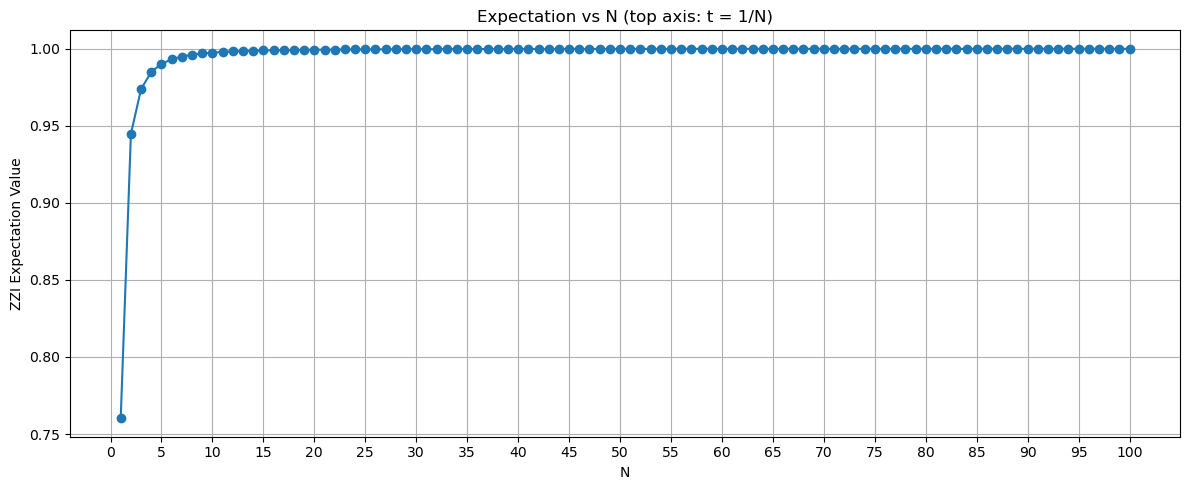

In [105]:
exp_val_given_T_one_axis(N=100)

In [83]:
pauli_ops = ['I', 'X', 'Y', 'Z']
observables = [''.join(p) for p in itertools.product(pauli_ops, repeat=3)]
print(observables)

['III', 'IIX', 'IIY', 'IIZ', 'IXI', 'IXX', 'IXY', 'IXZ', 'IYI', 'IYX', 'IYY', 'IYZ', 'IZI', 'IZX', 'IZY', 'IZZ', 'XII', 'XIX', 'XIY', 'XIZ', 'XXI', 'XXX', 'XXY', 'XXZ', 'XYI', 'XYX', 'XYY', 'XYZ', 'XZI', 'XZX', 'XZY', 'XZZ', 'YII', 'YIX', 'YIY', 'YIZ', 'YXI', 'YXX', 'YXY', 'YXZ', 'YYI', 'YYX', 'YYY', 'YYZ', 'YZI', 'YZX', 'YZY', 'YZZ', 'ZII', 'ZIX', 'ZIY', 'ZIZ', 'ZXI', 'ZXX', 'ZXY', 'ZXZ', 'ZYI', 'ZYX', 'ZYY', 'ZYZ', 'ZZI', 'ZZX', 'ZZY', 'ZZZ']


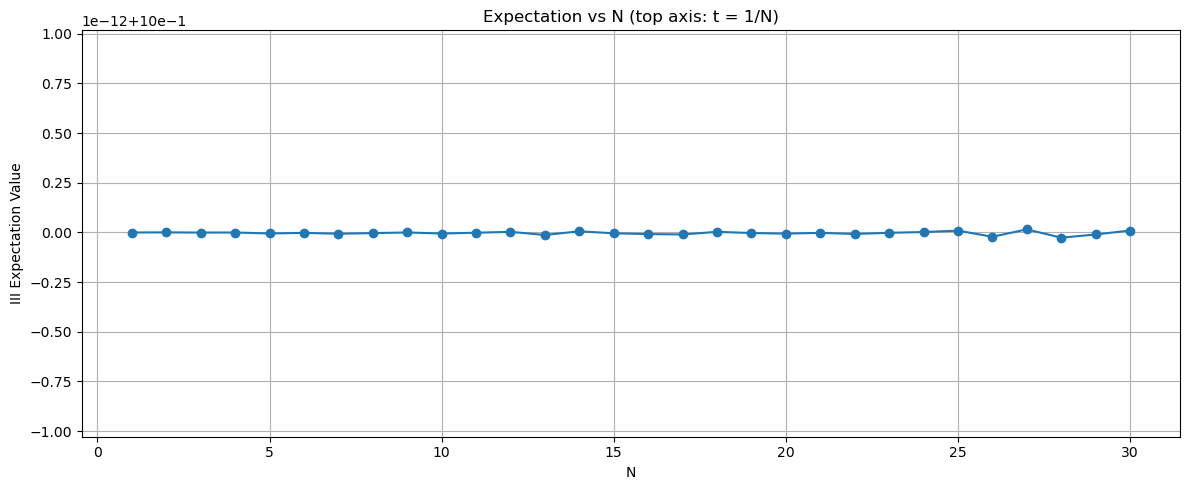

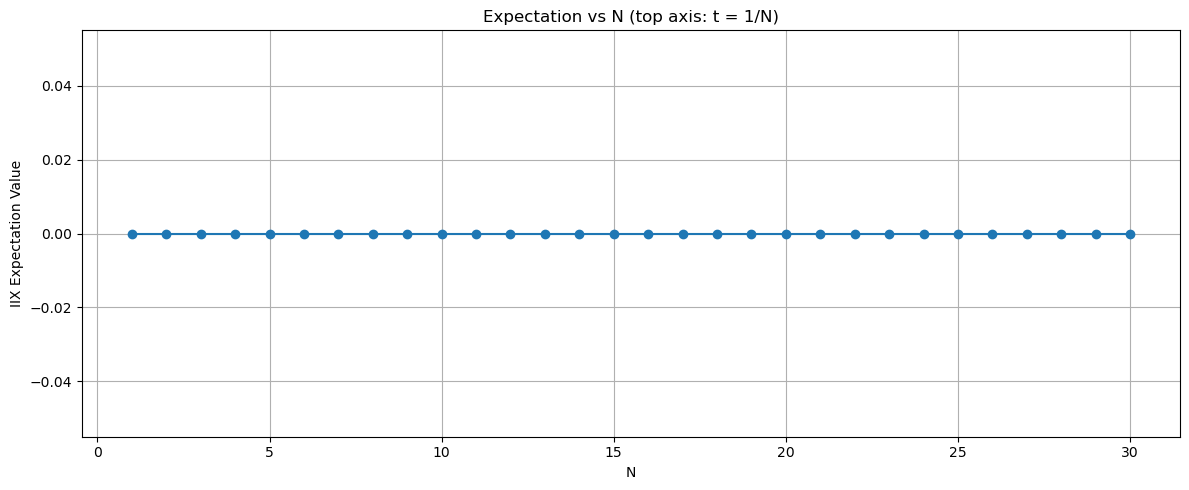

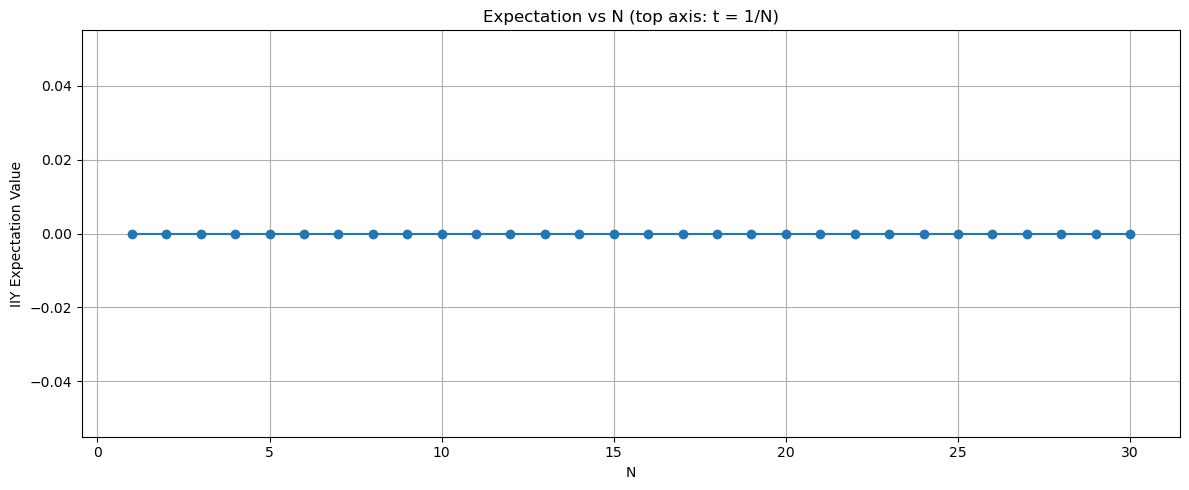

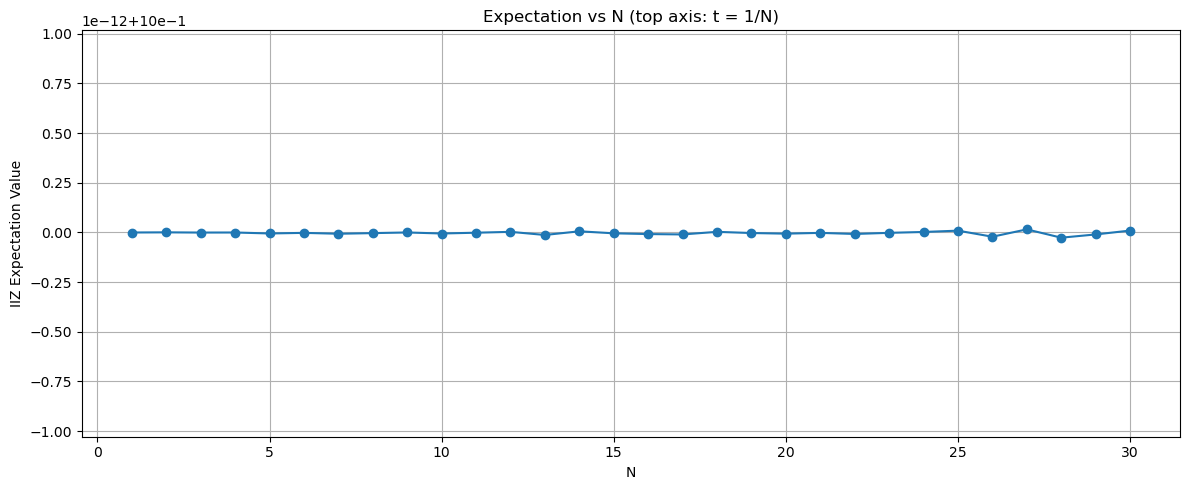

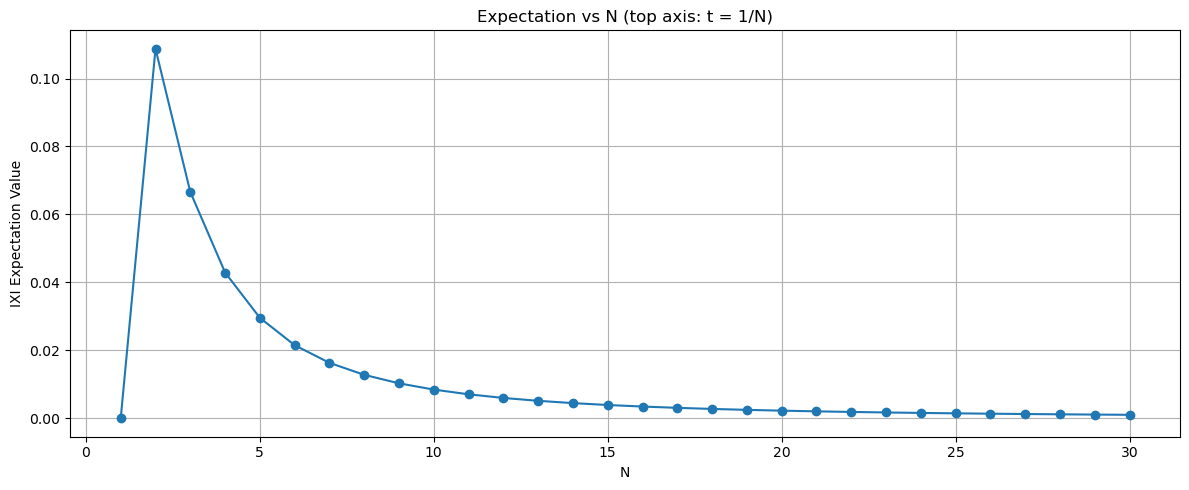

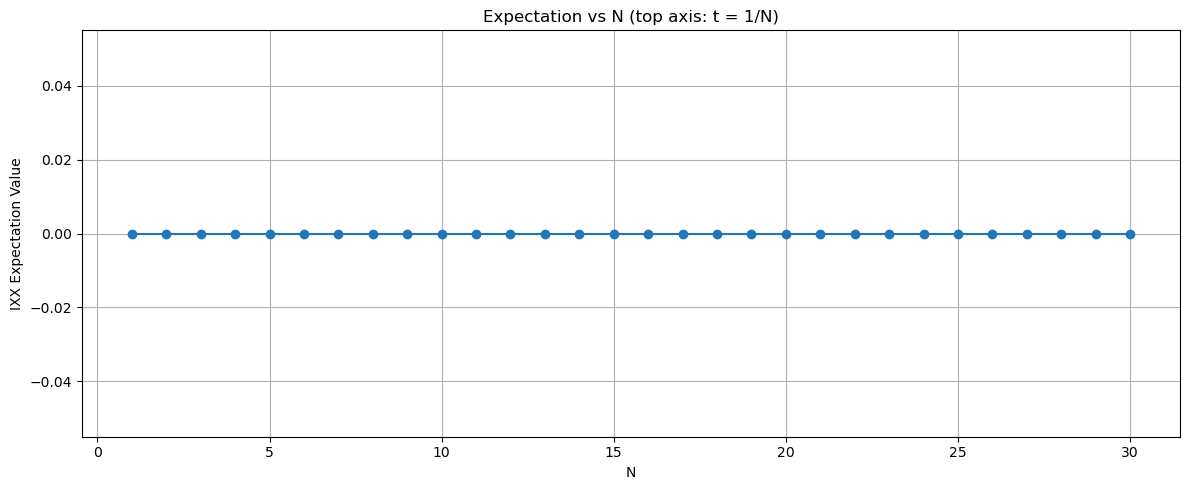

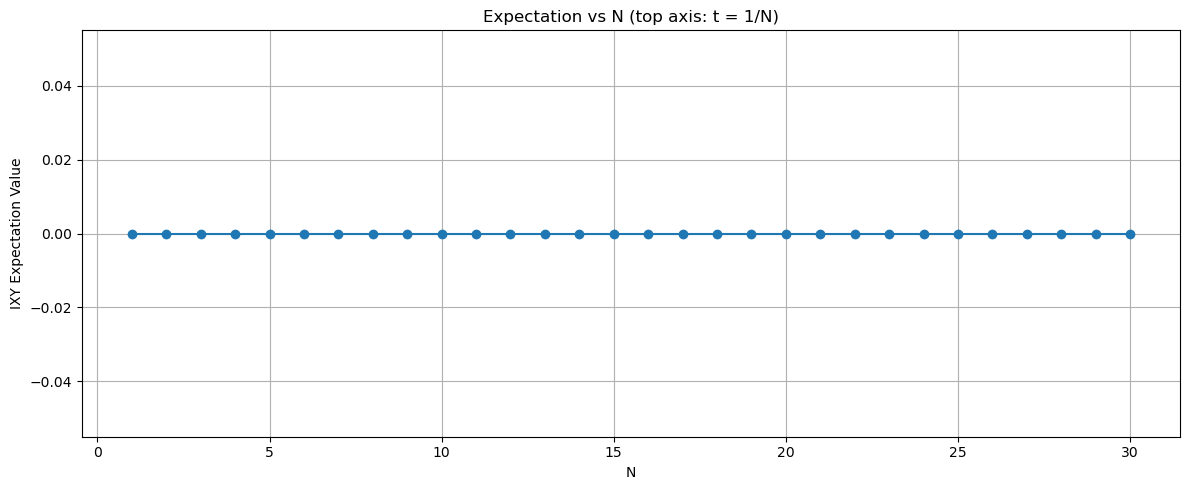

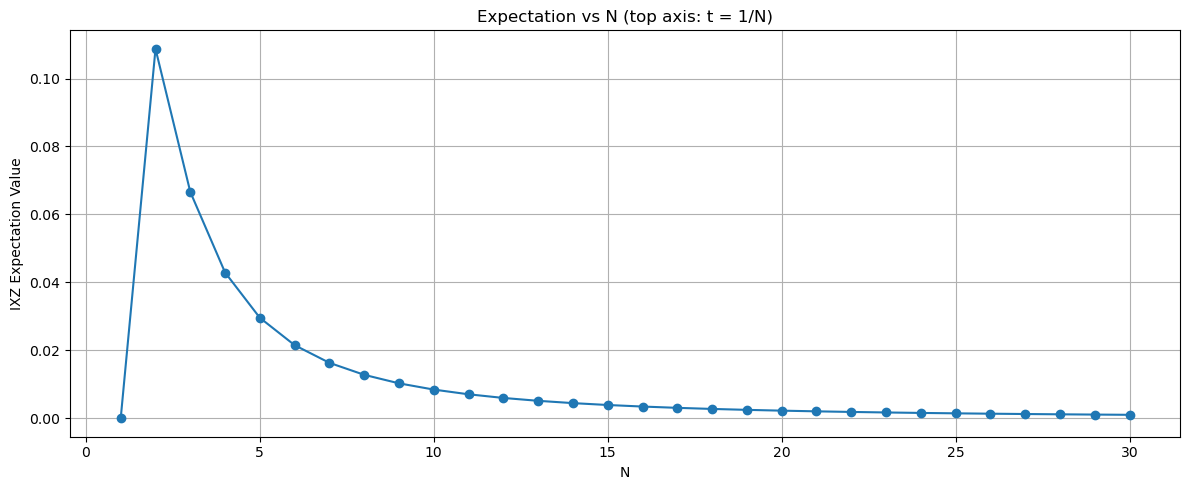

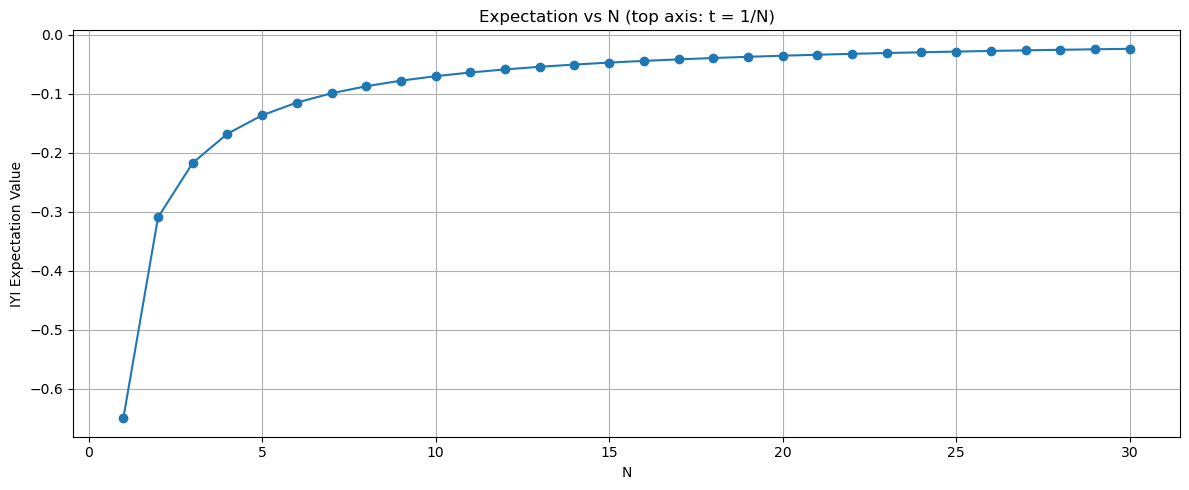

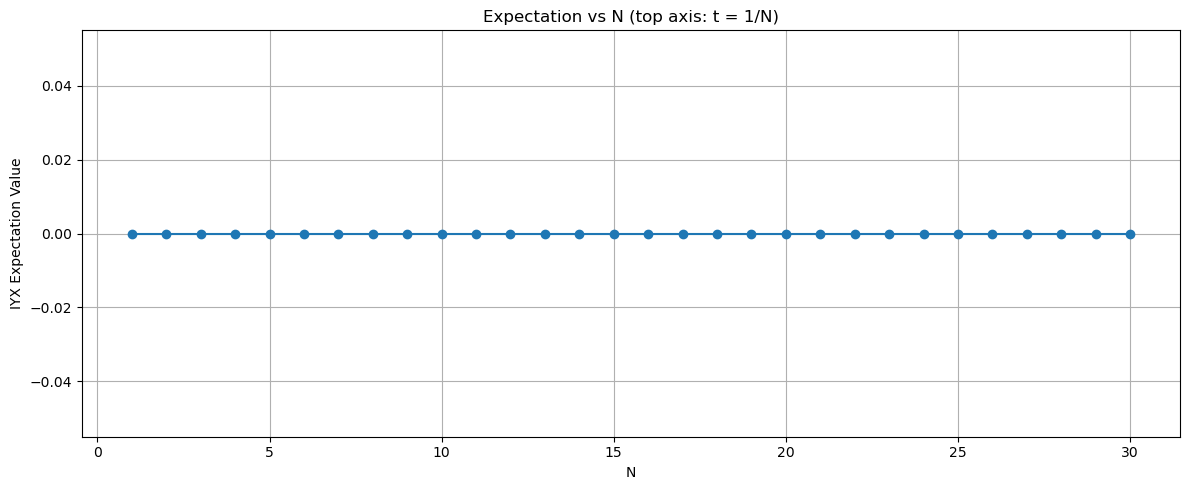

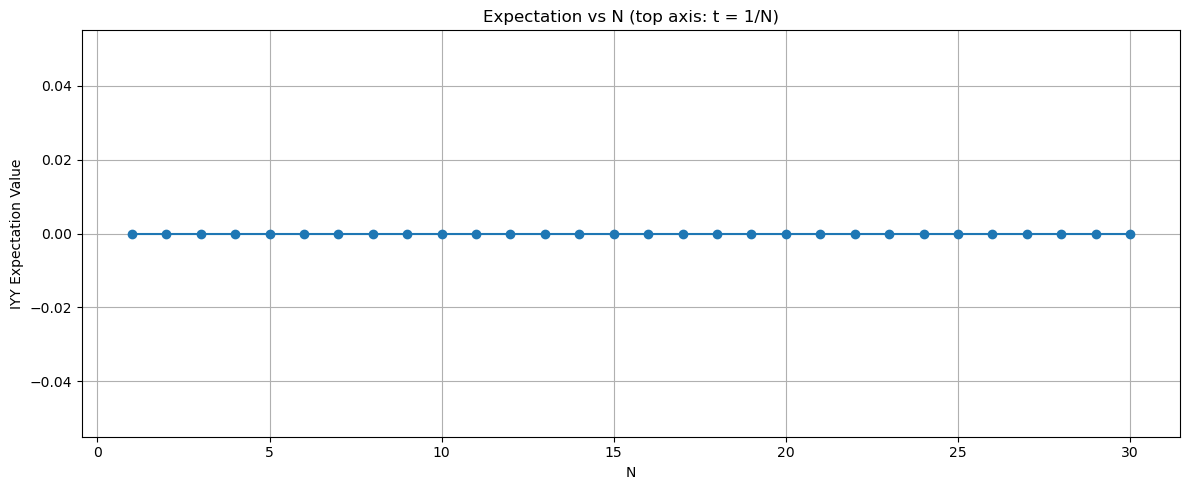

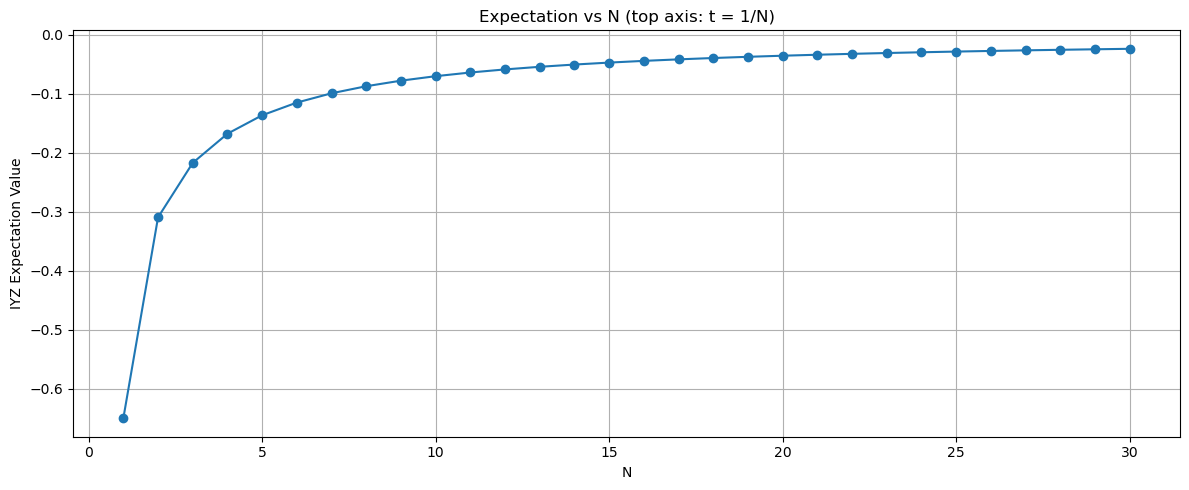

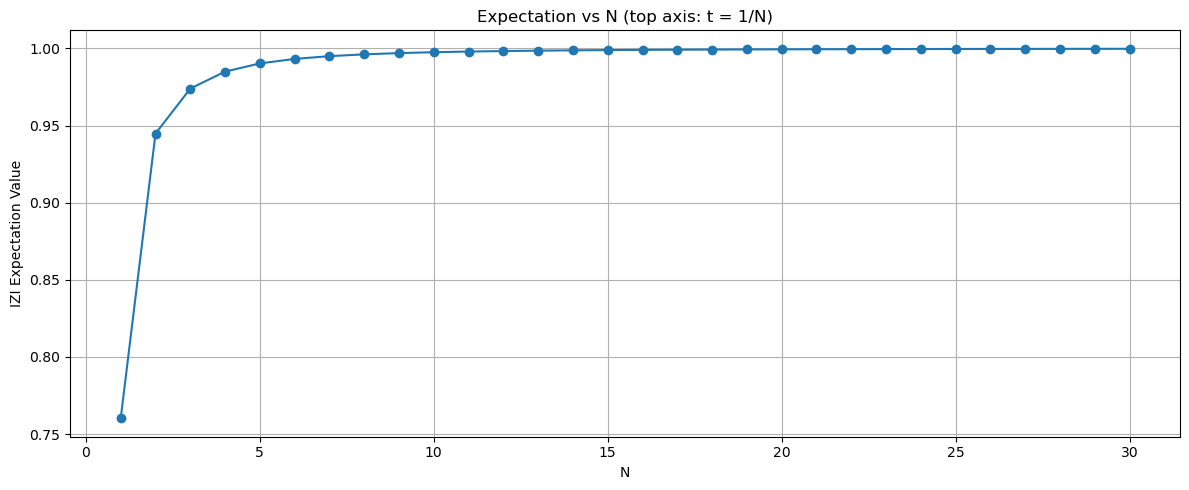

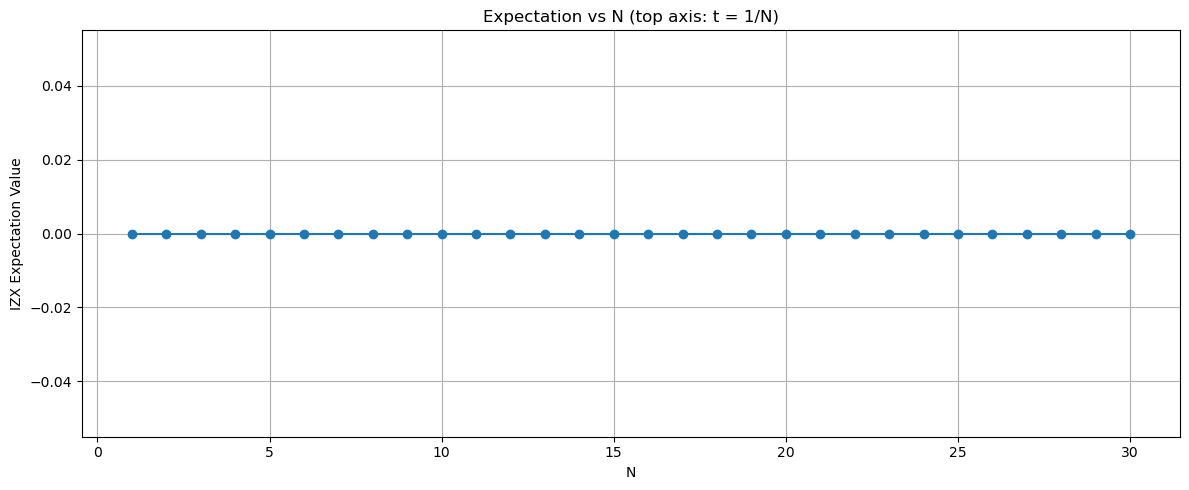

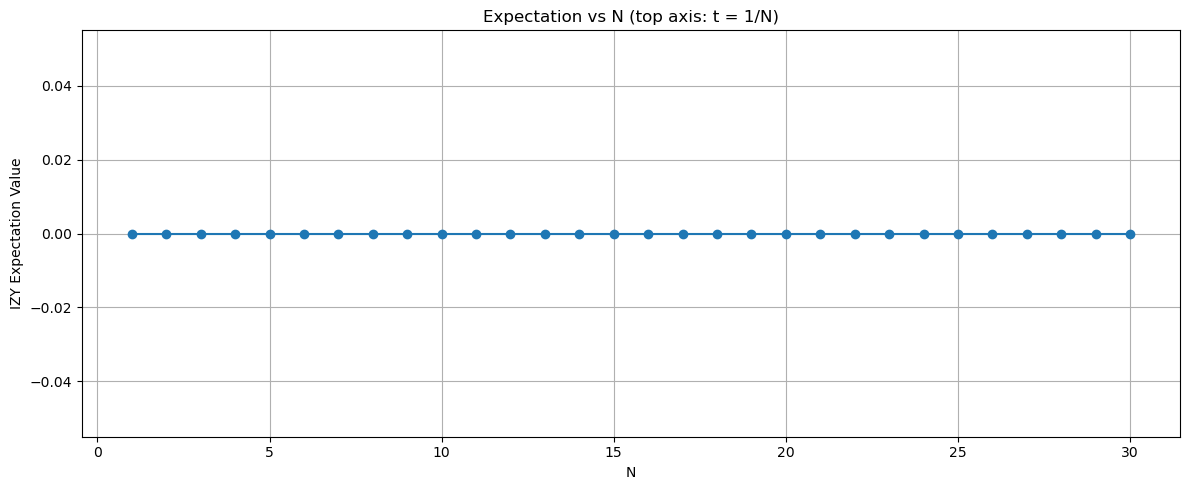

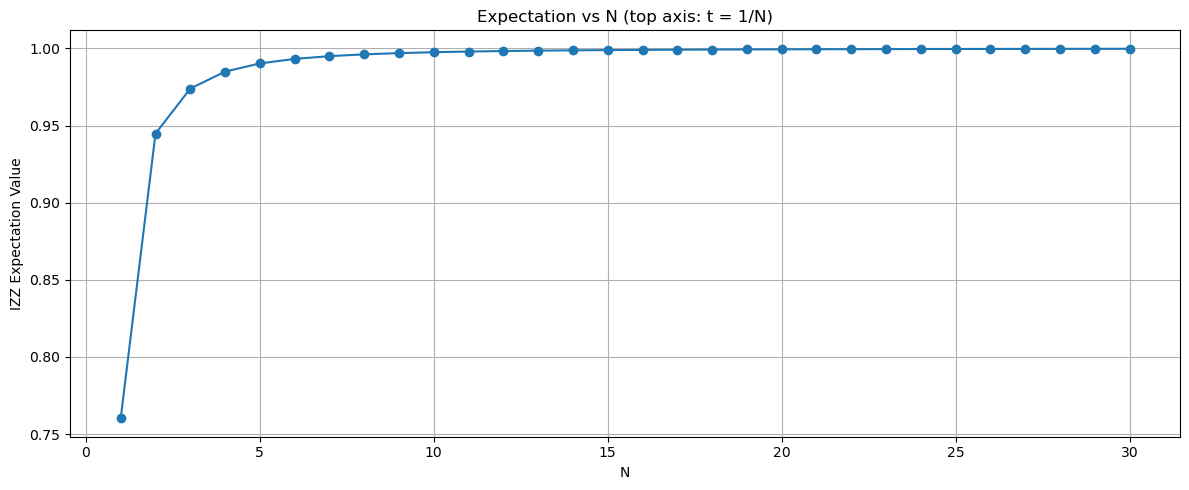

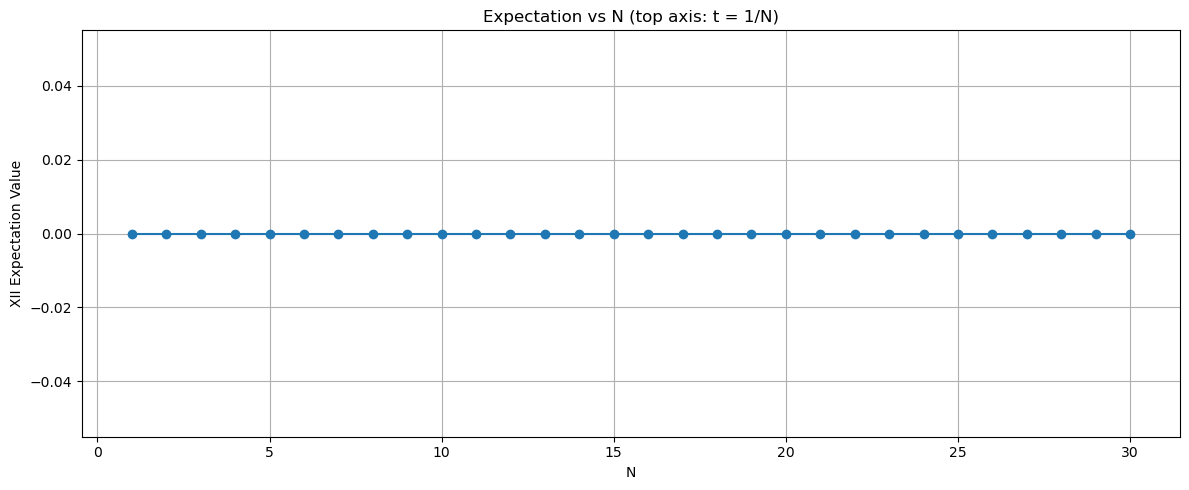

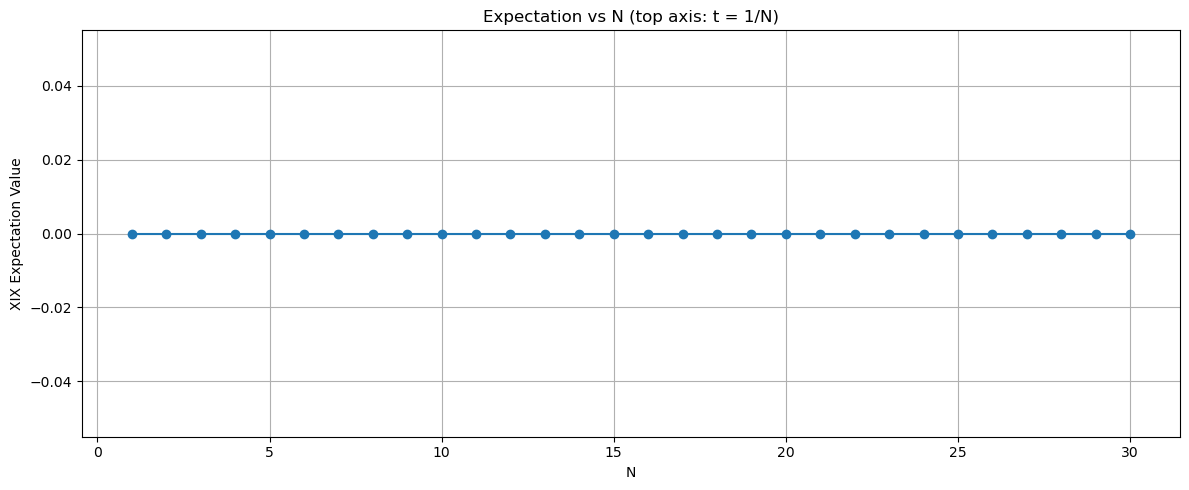

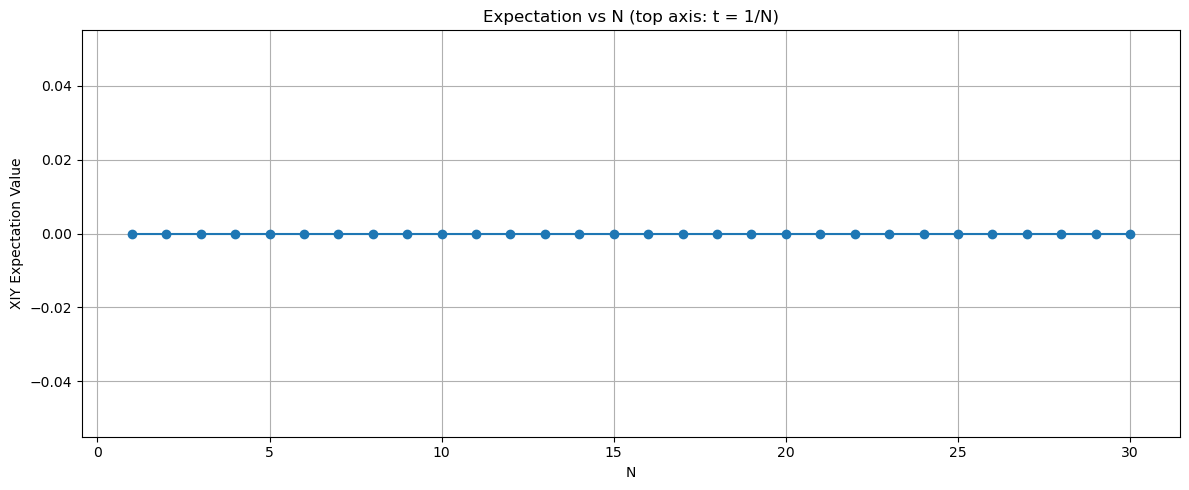

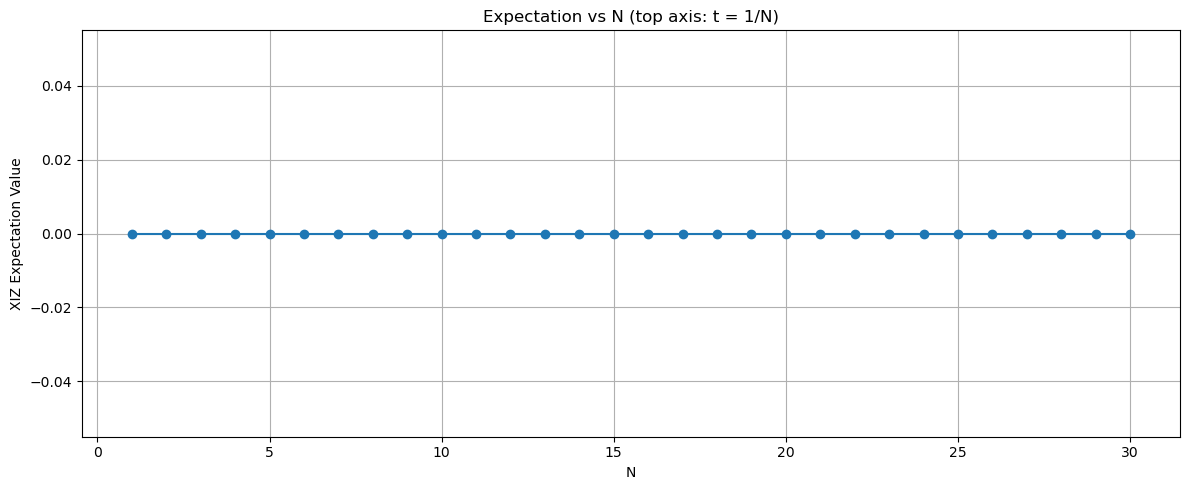

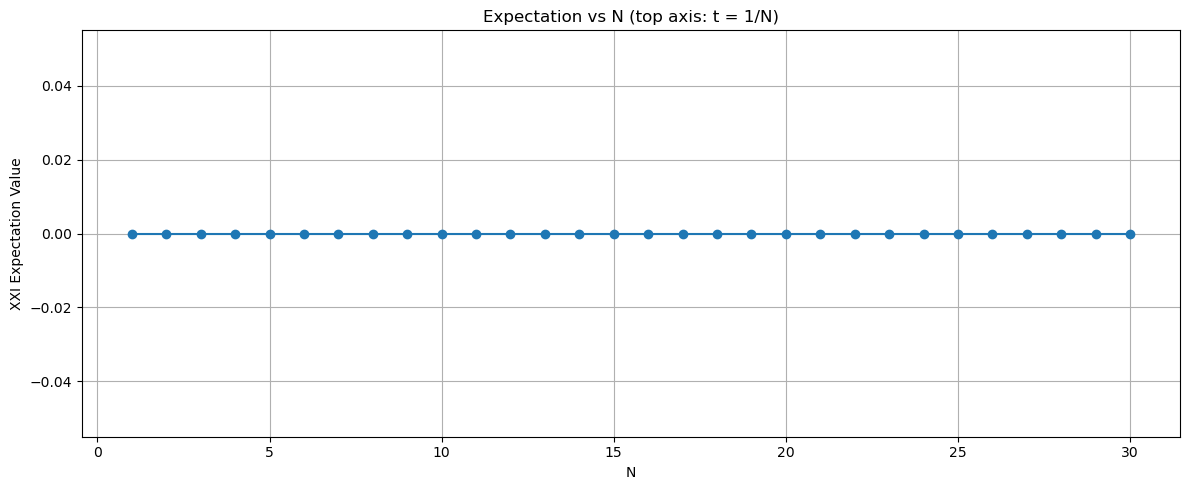

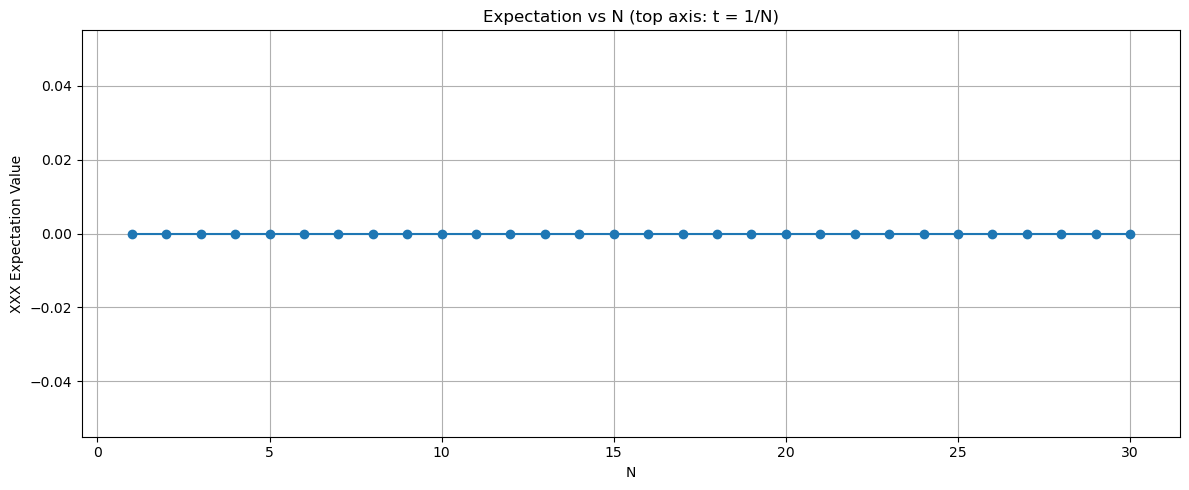

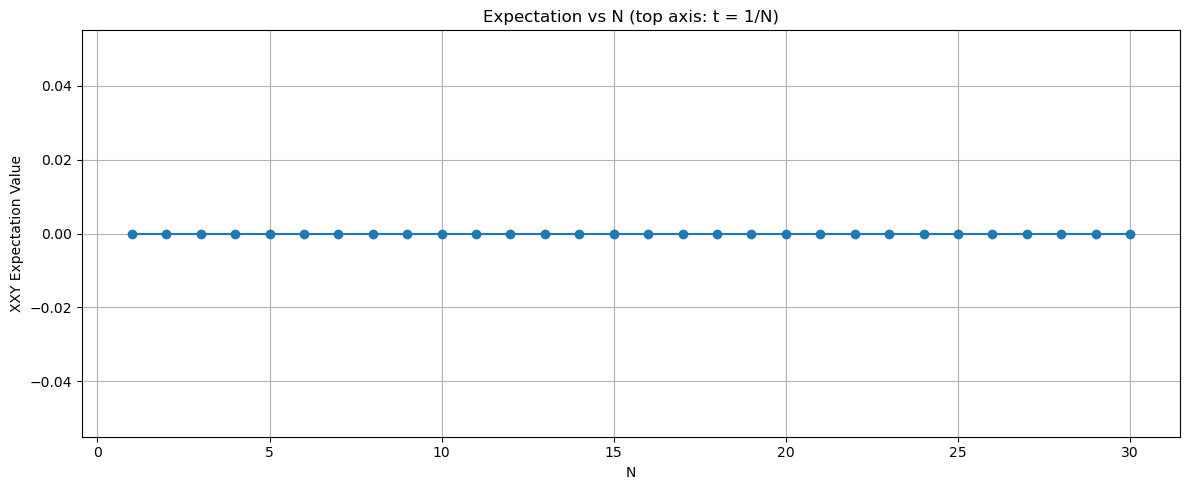

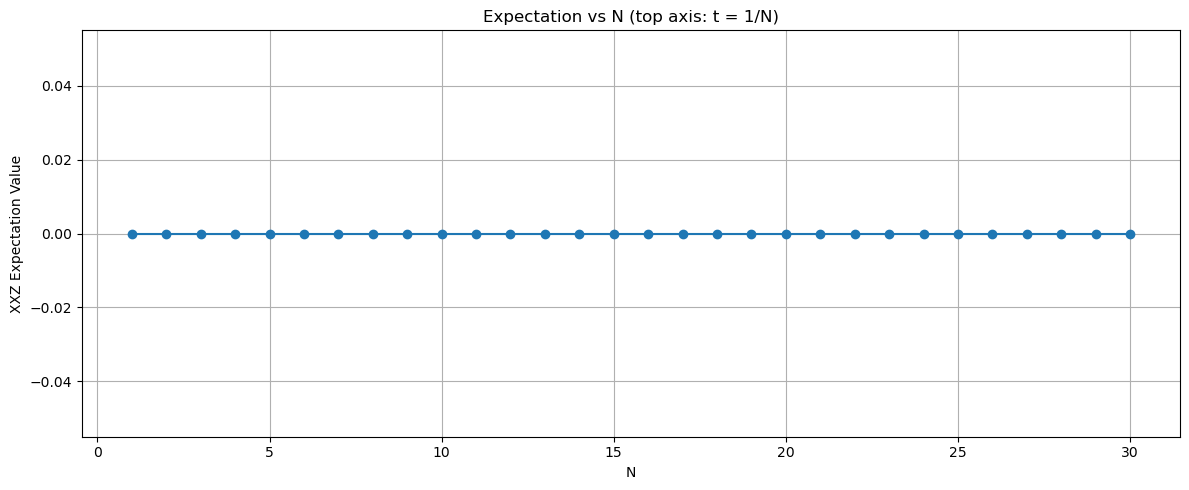

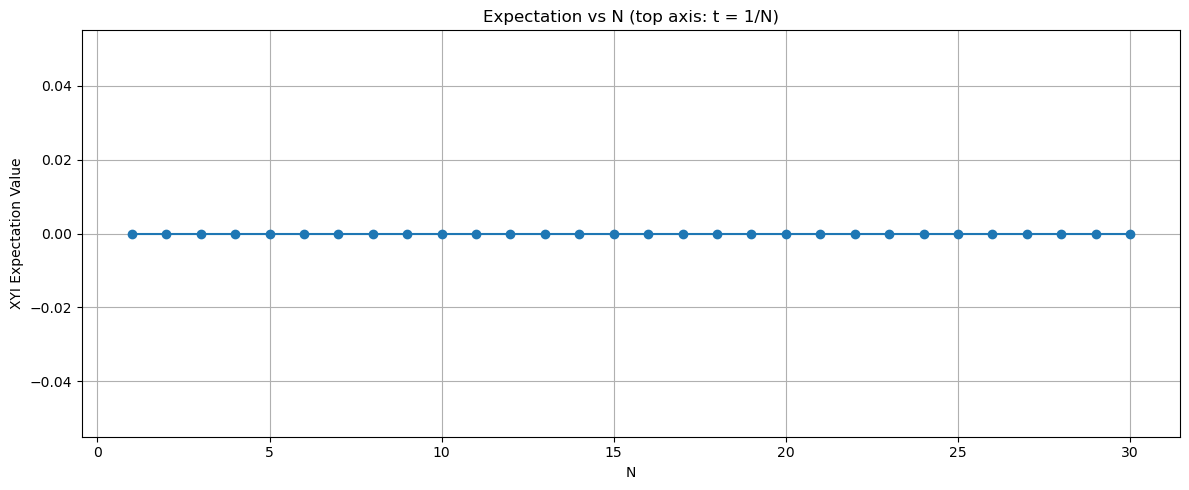

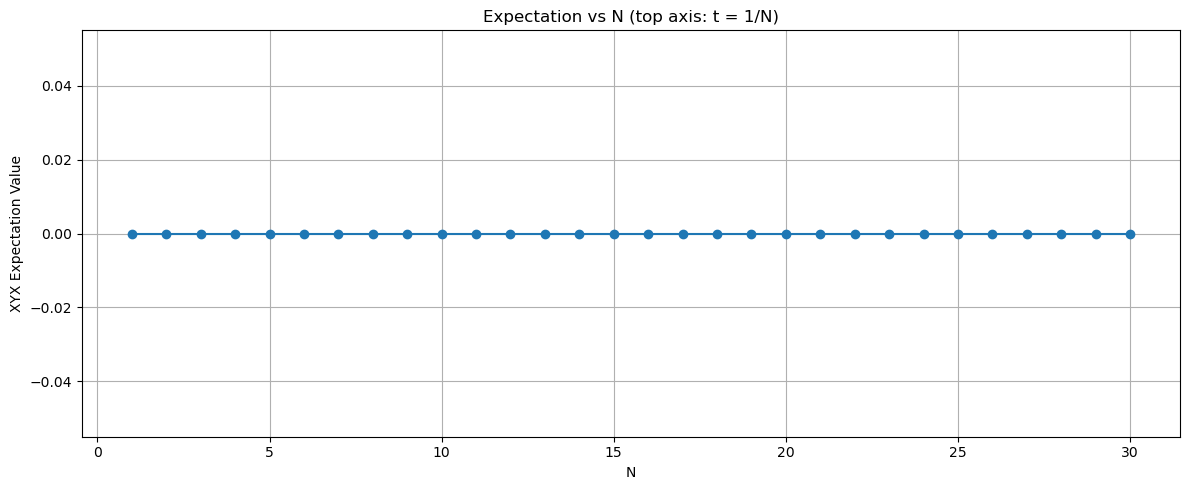

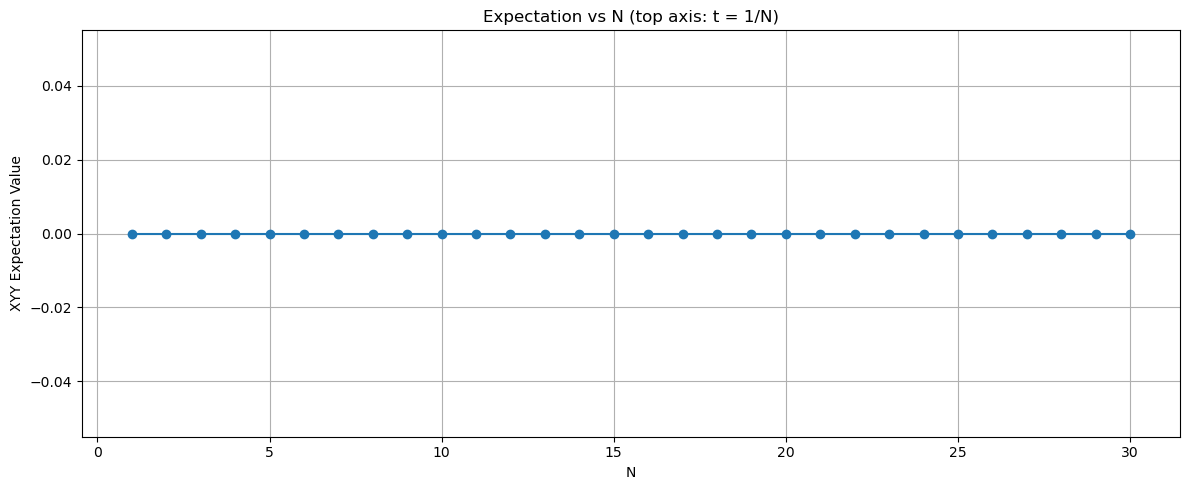

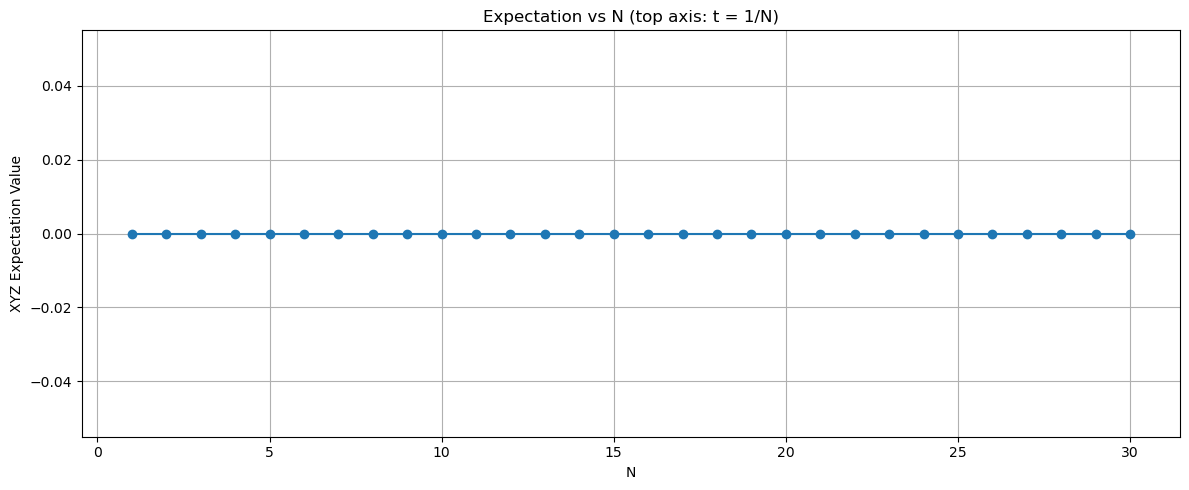

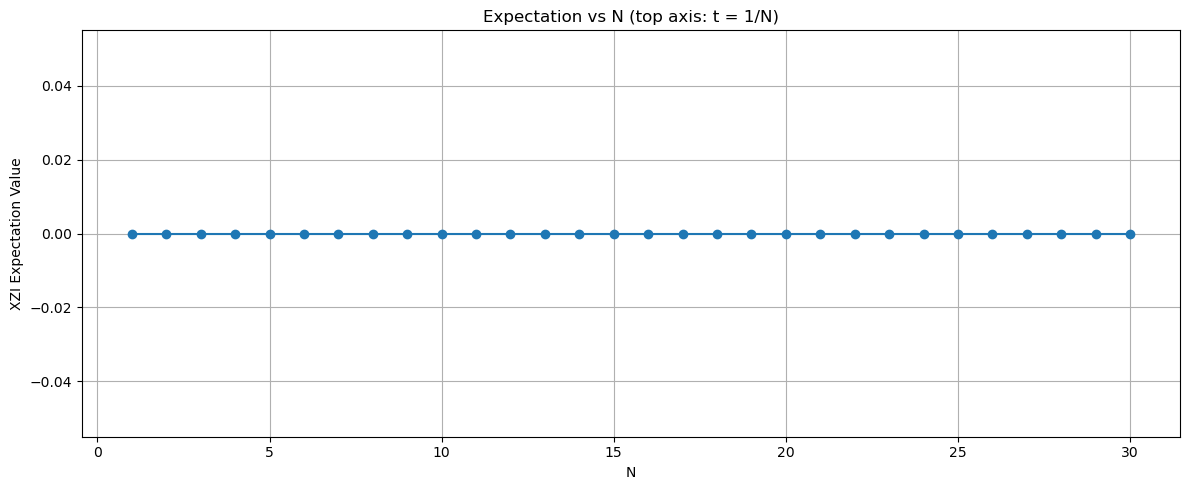

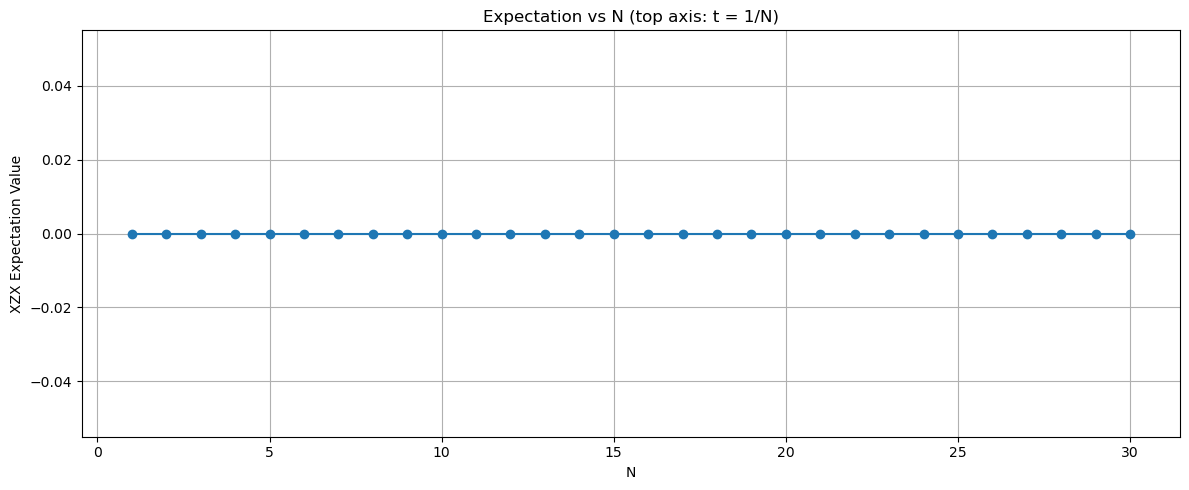

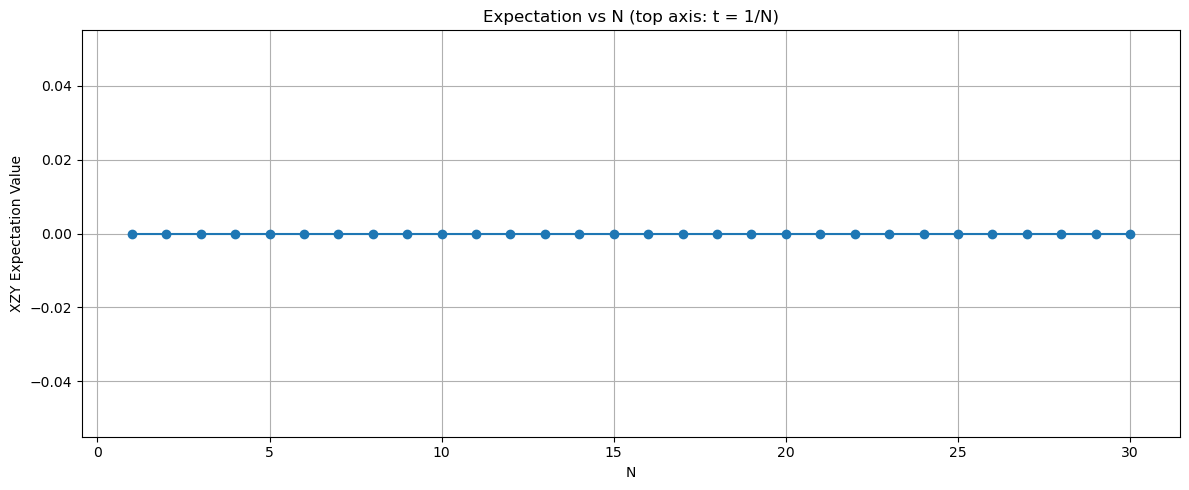

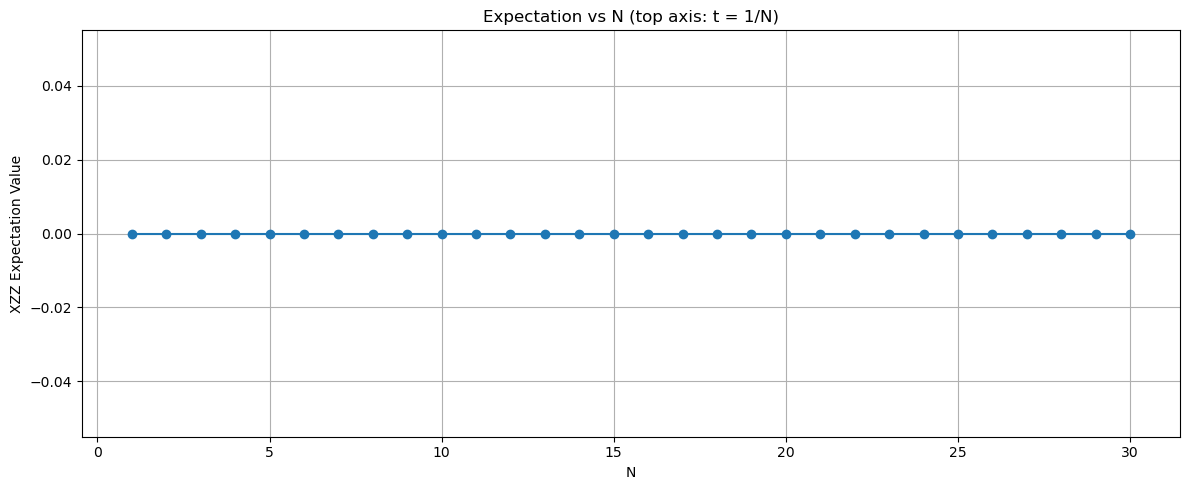

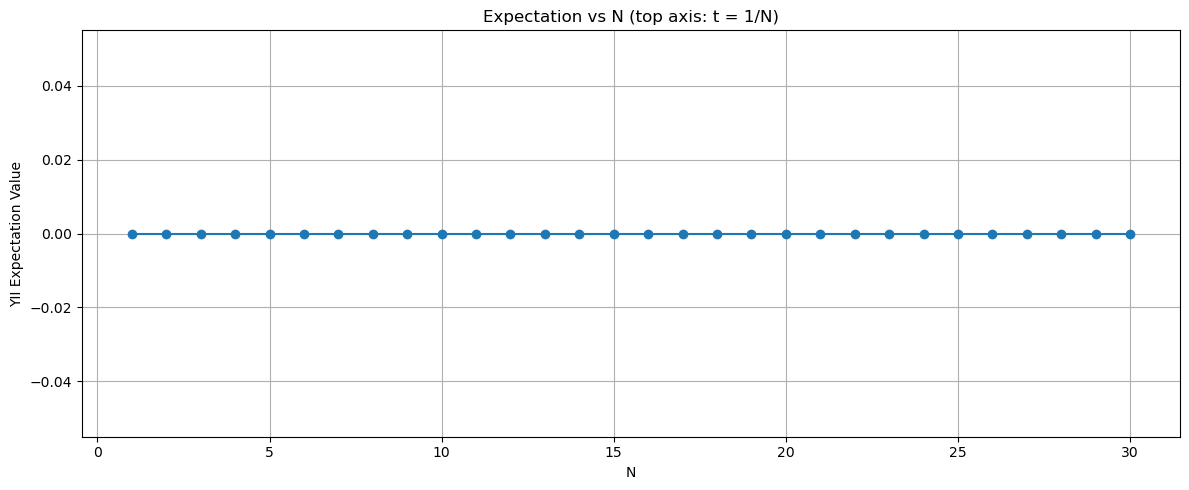

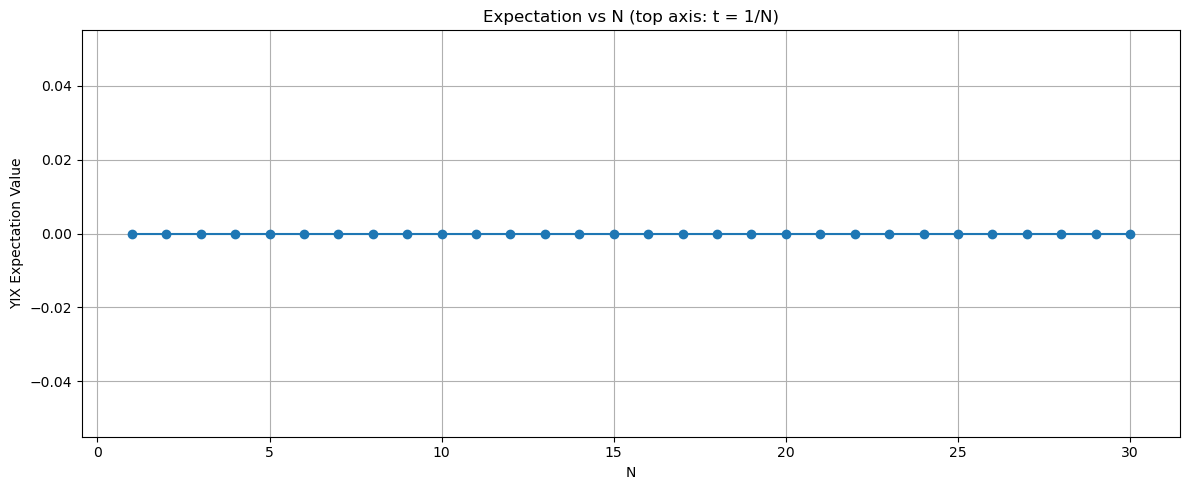

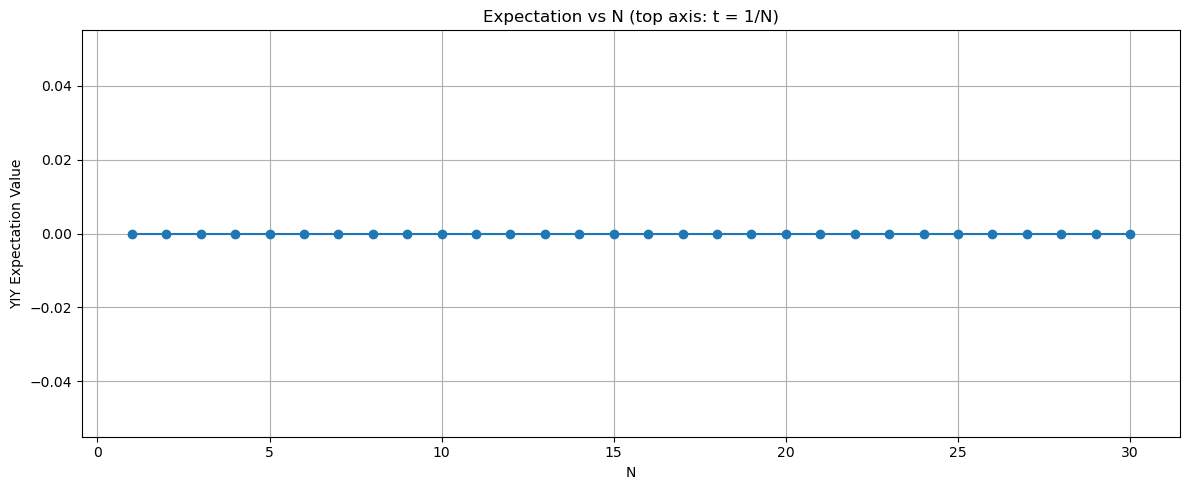

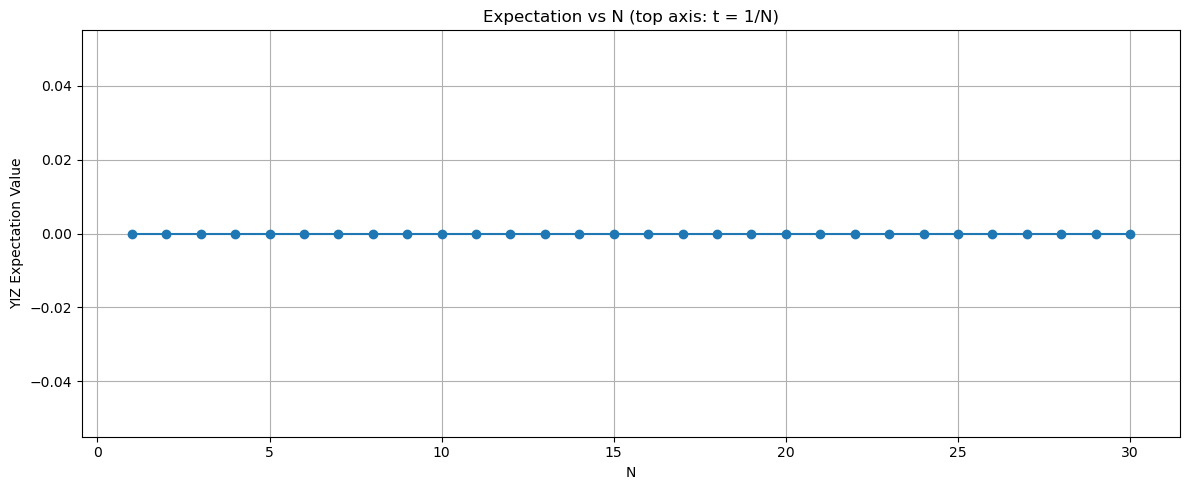

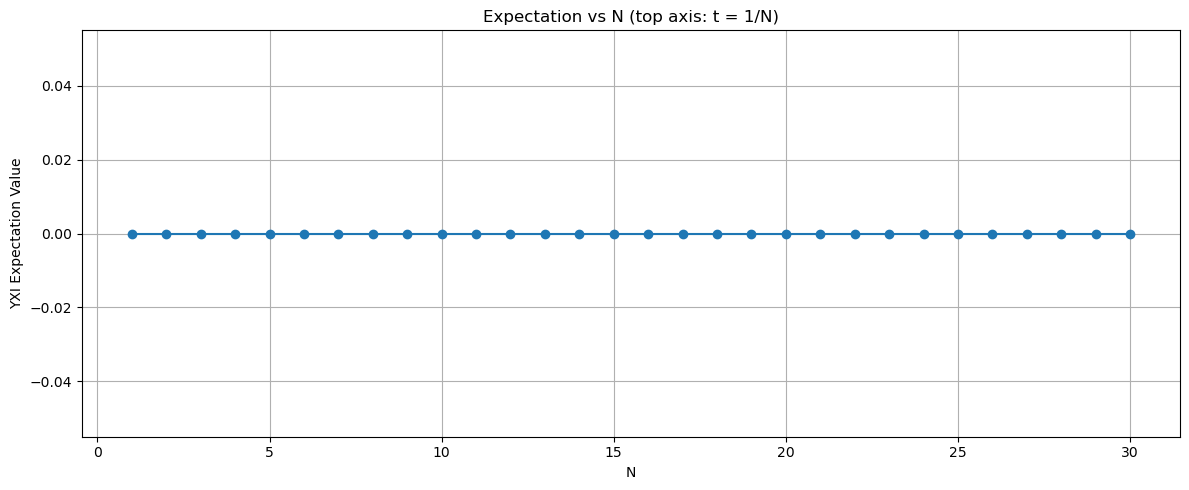

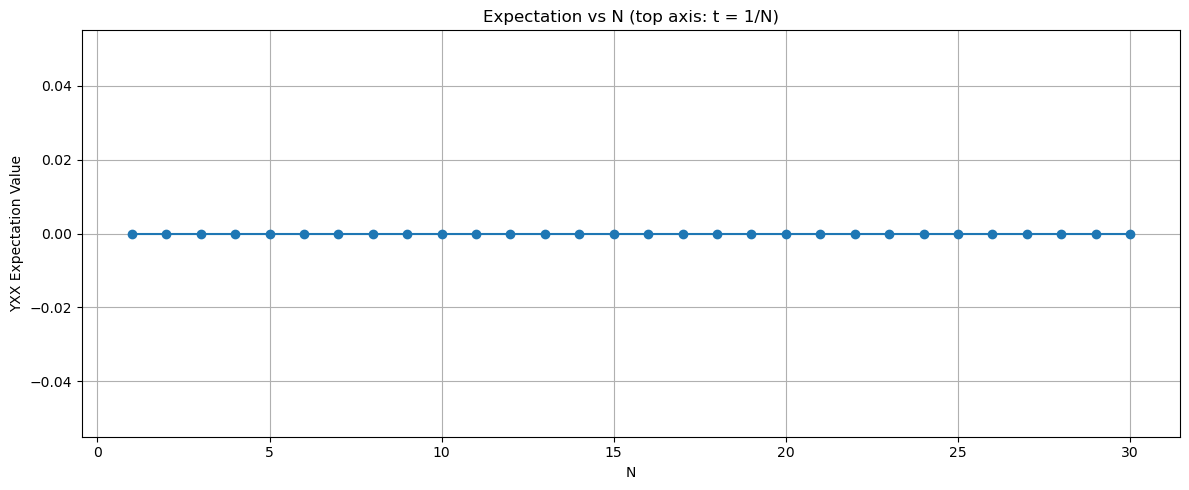

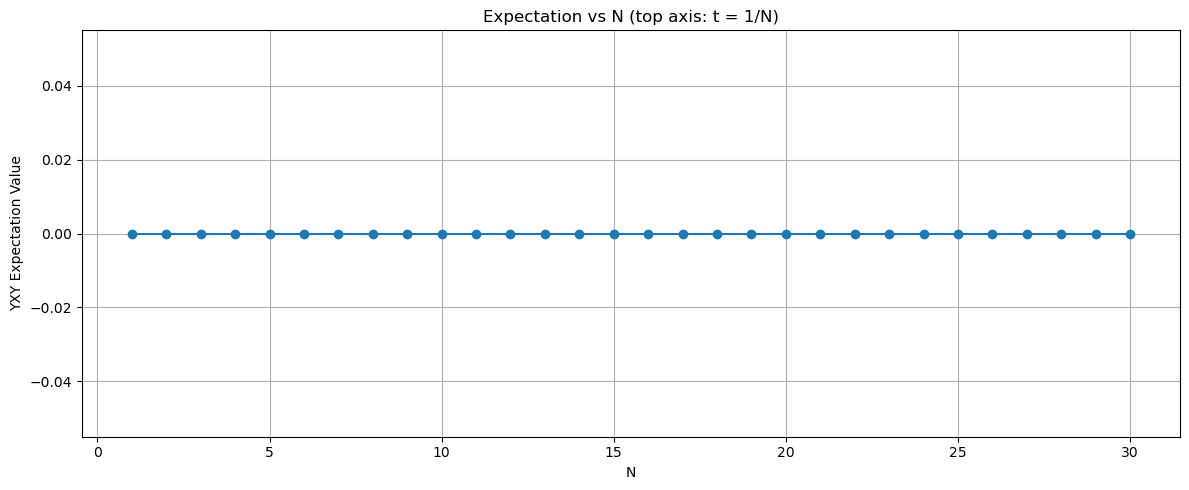

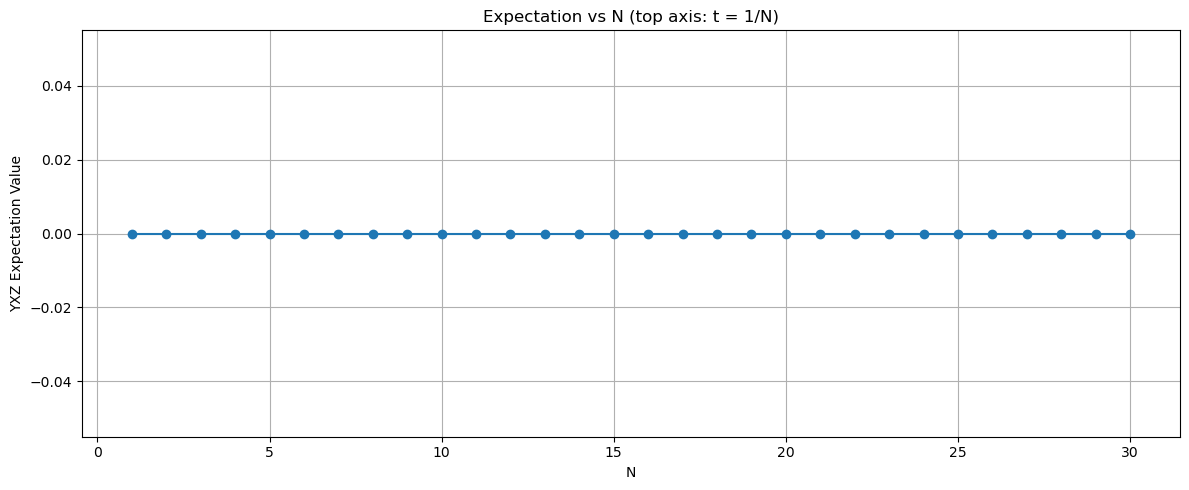

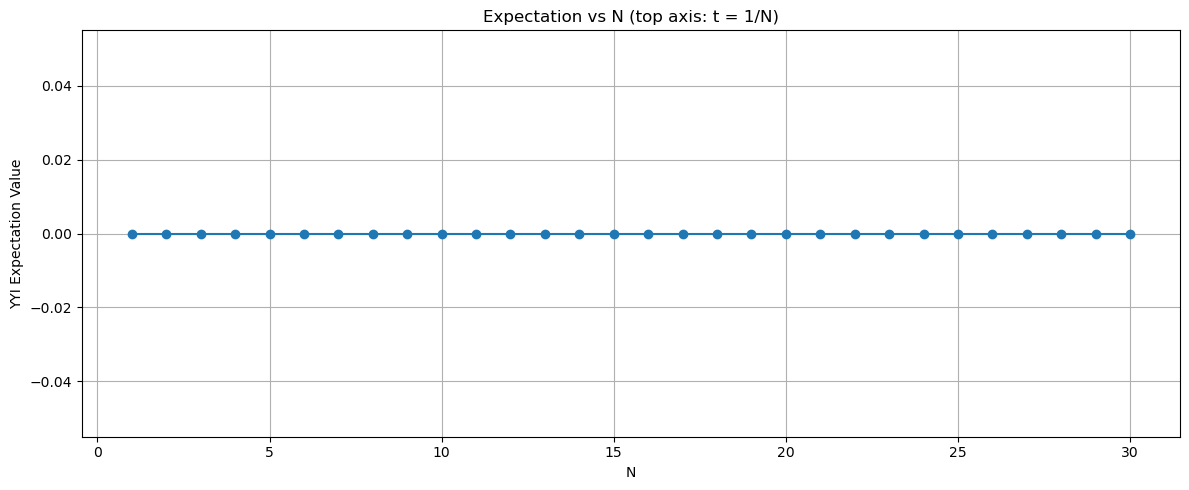

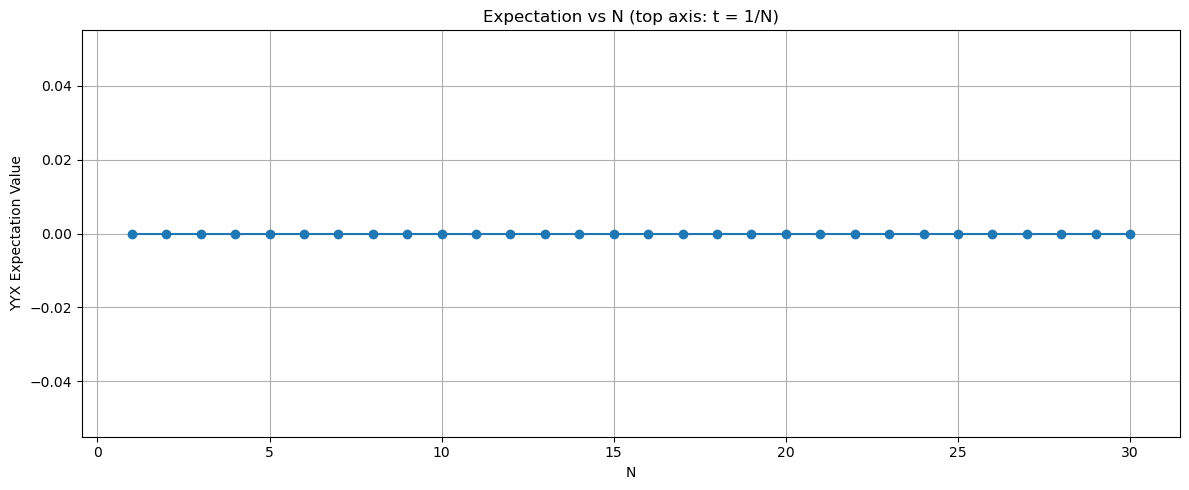

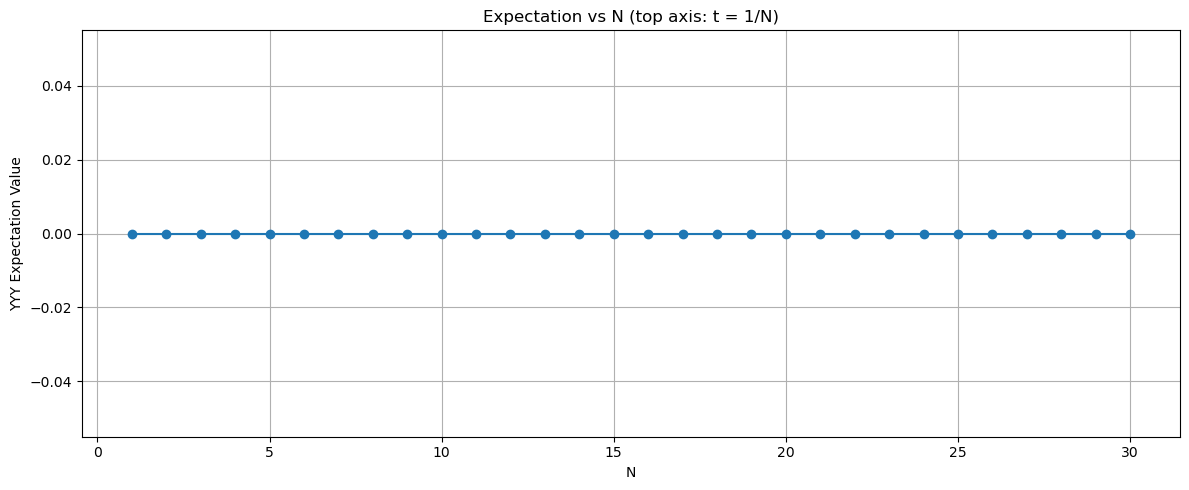

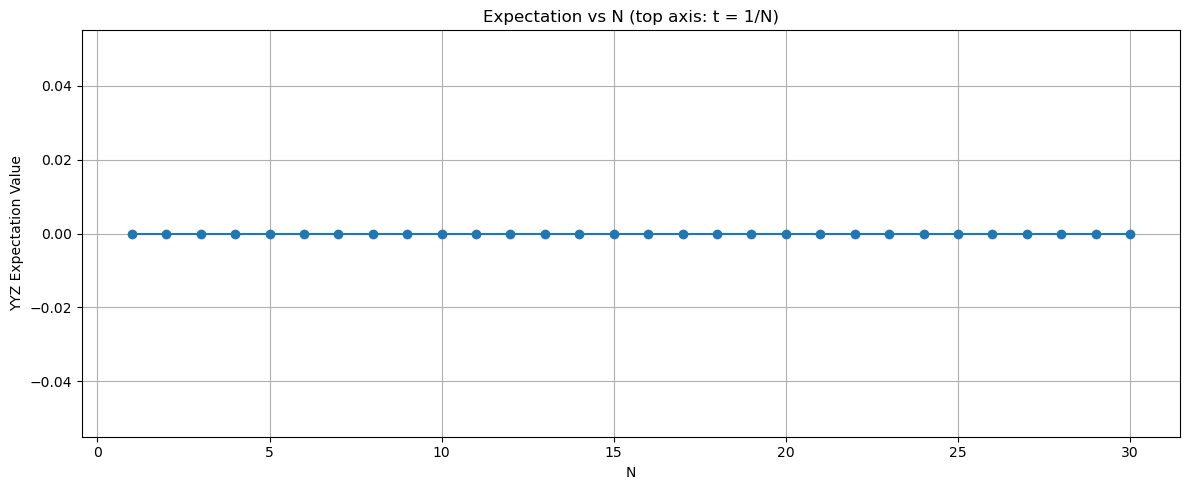

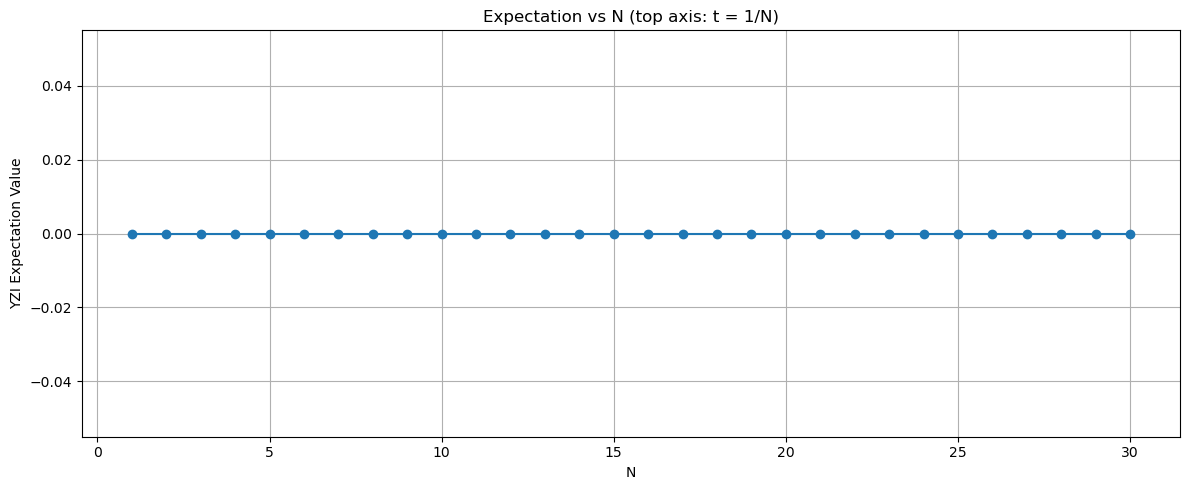

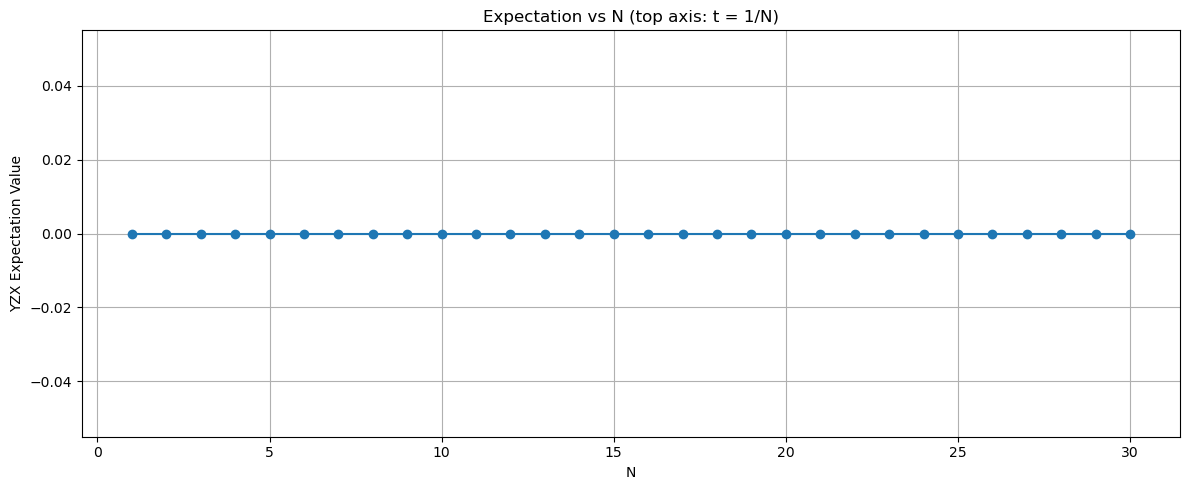

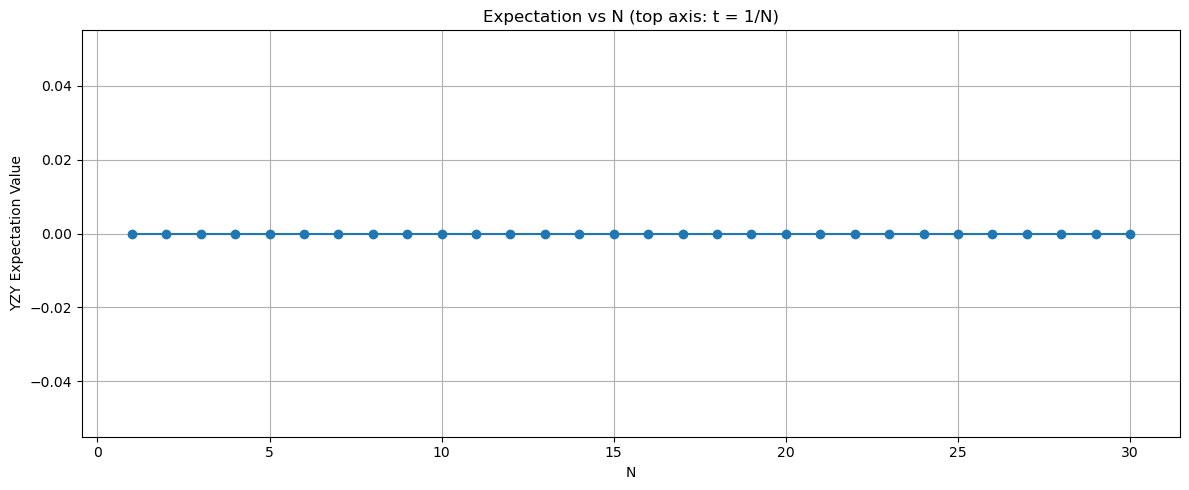

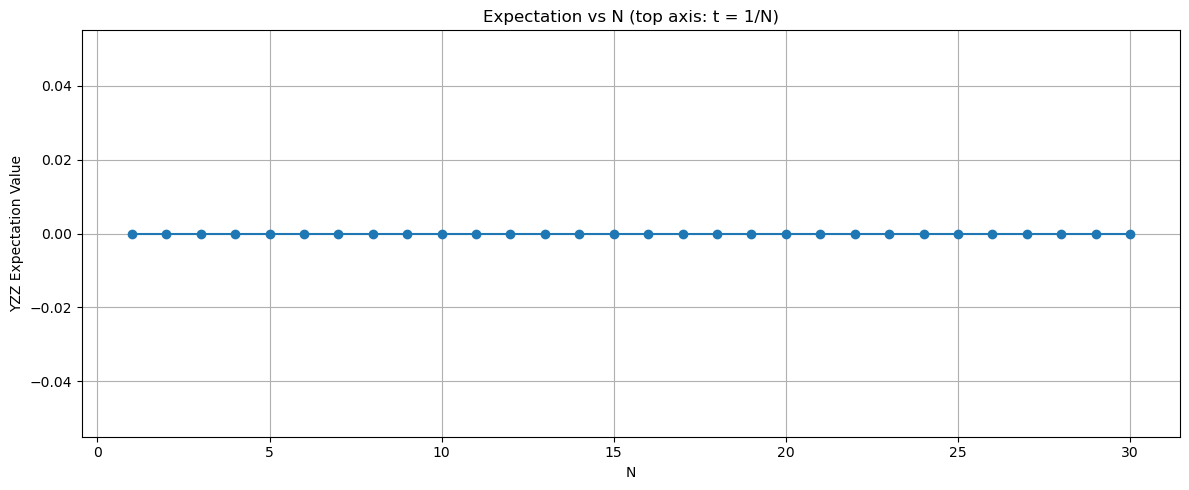

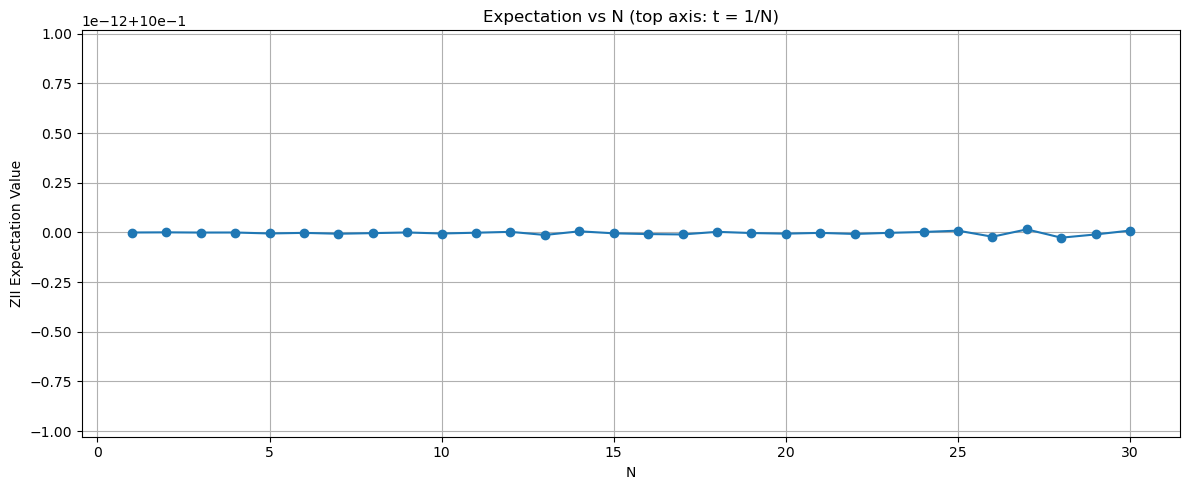

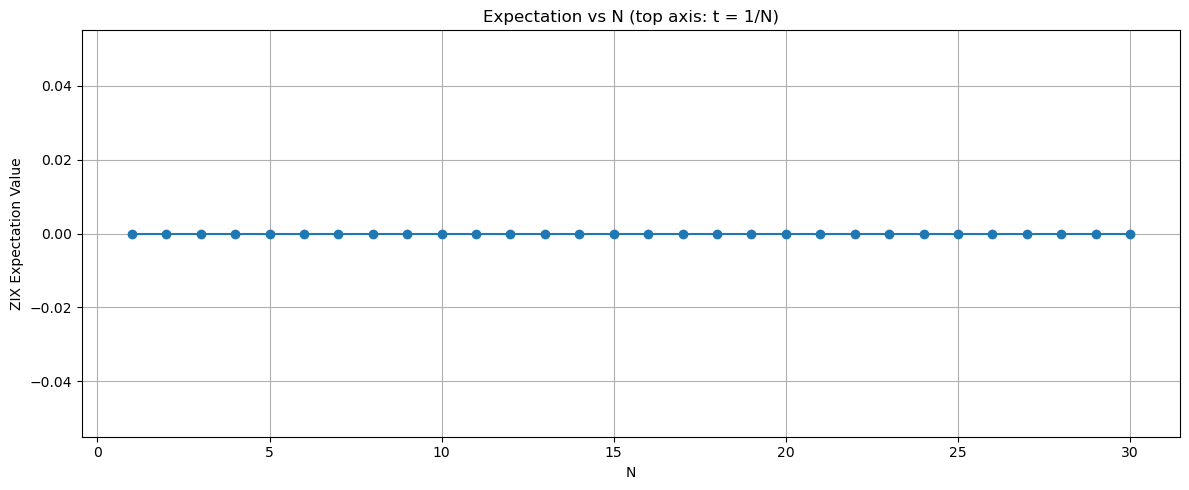

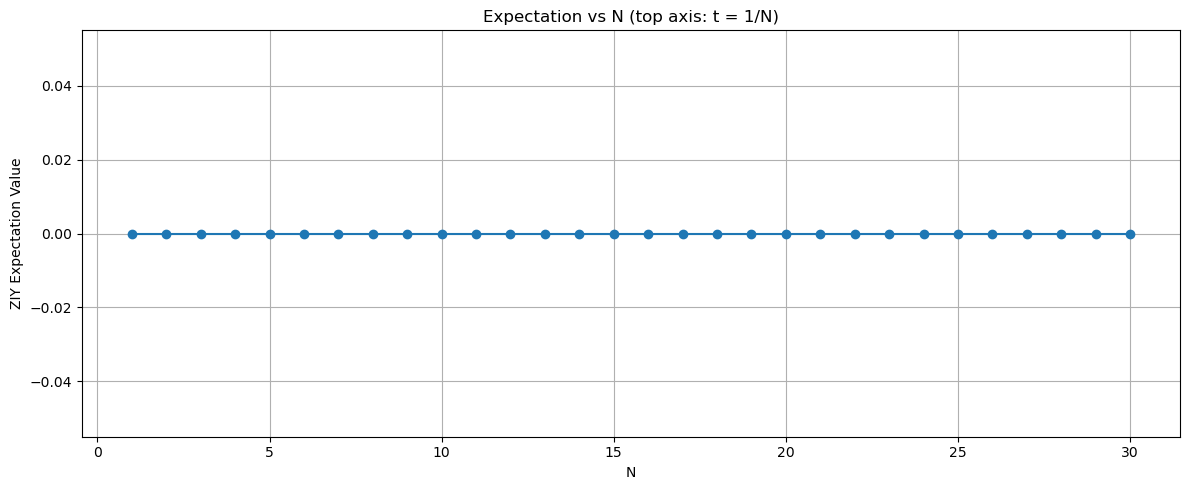

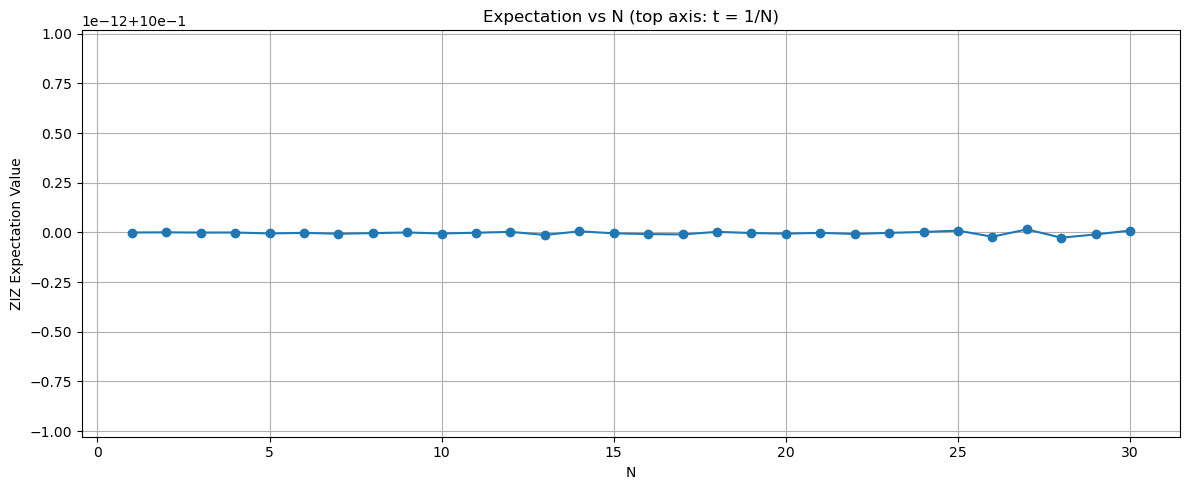

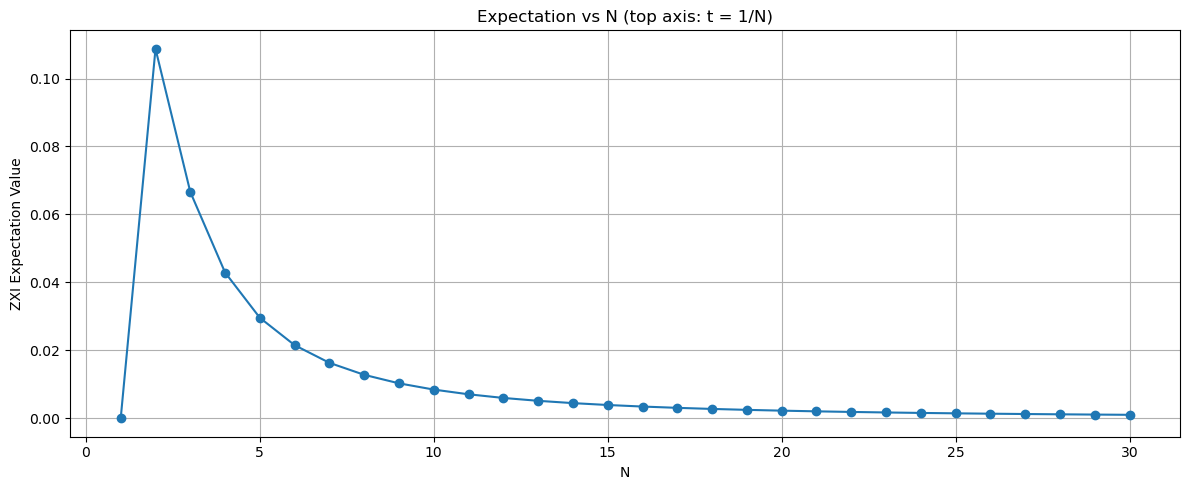

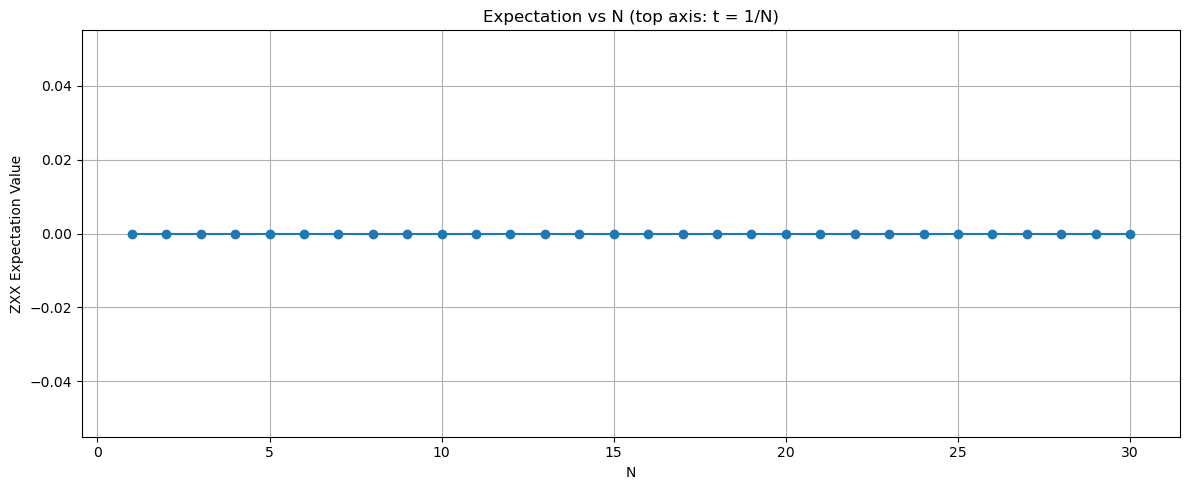

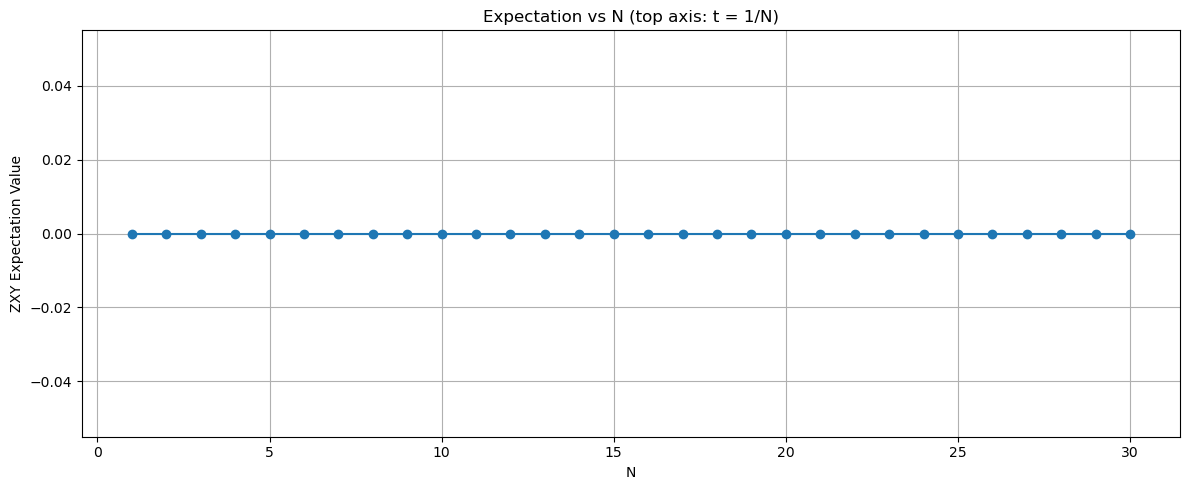

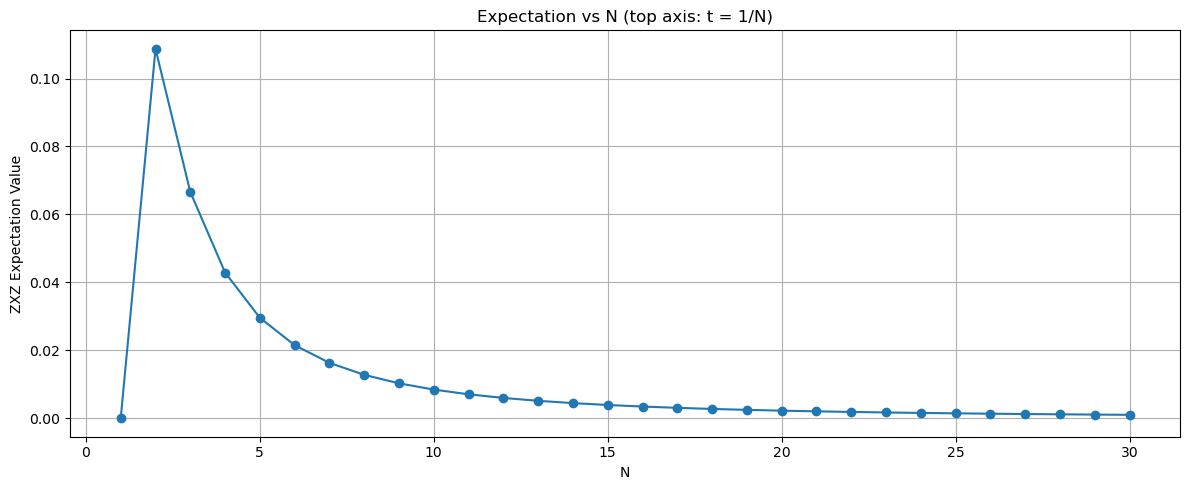

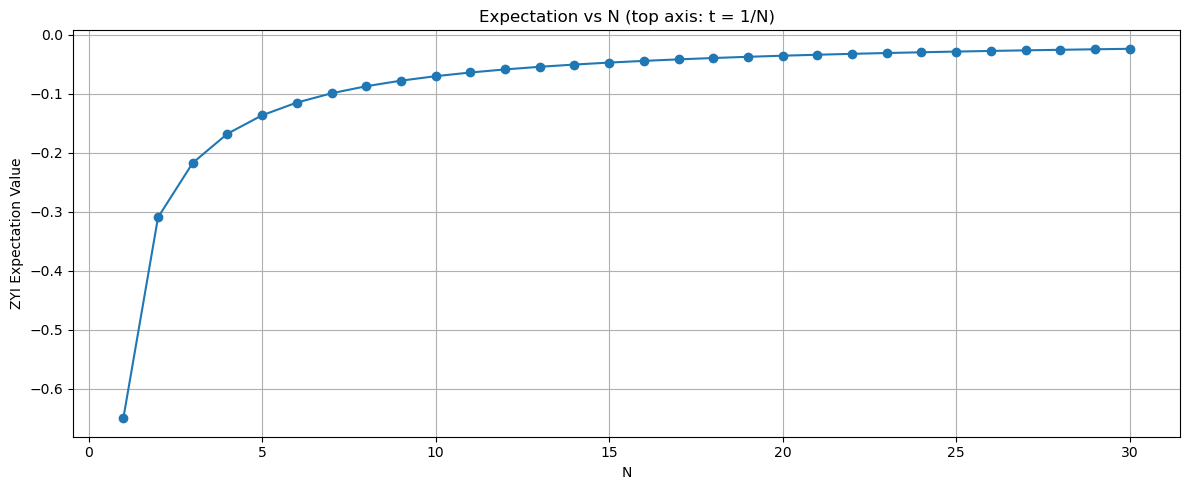

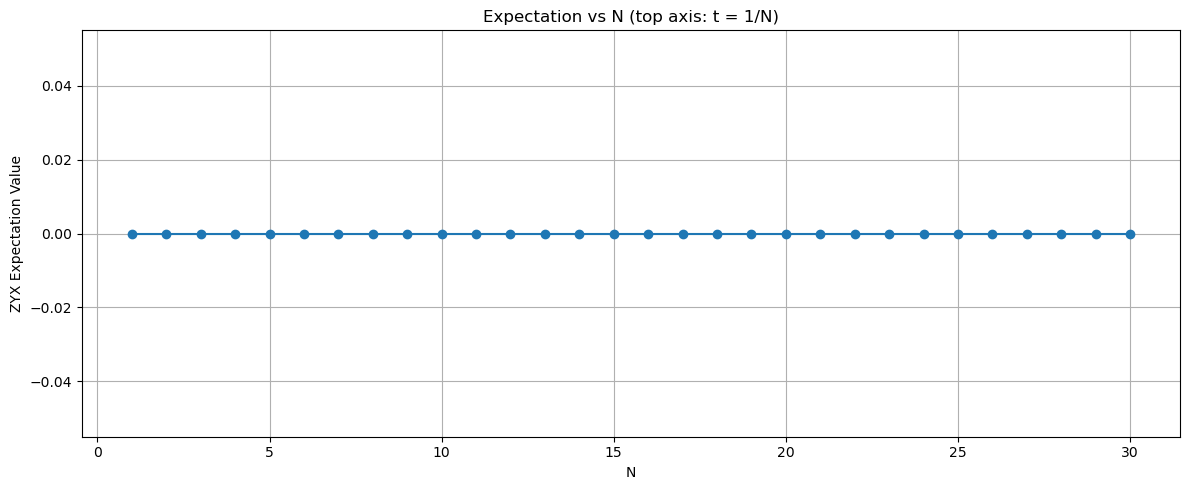

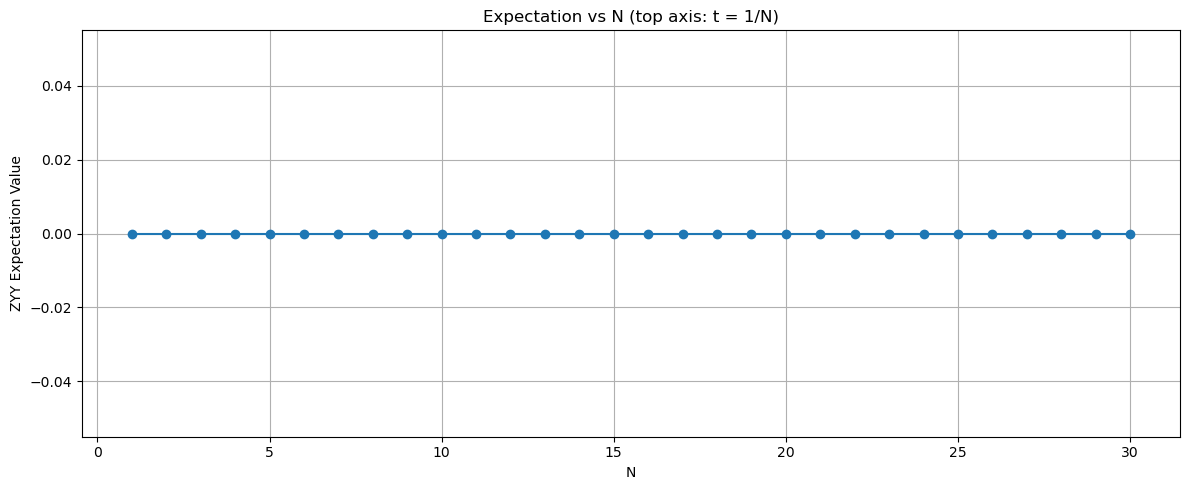

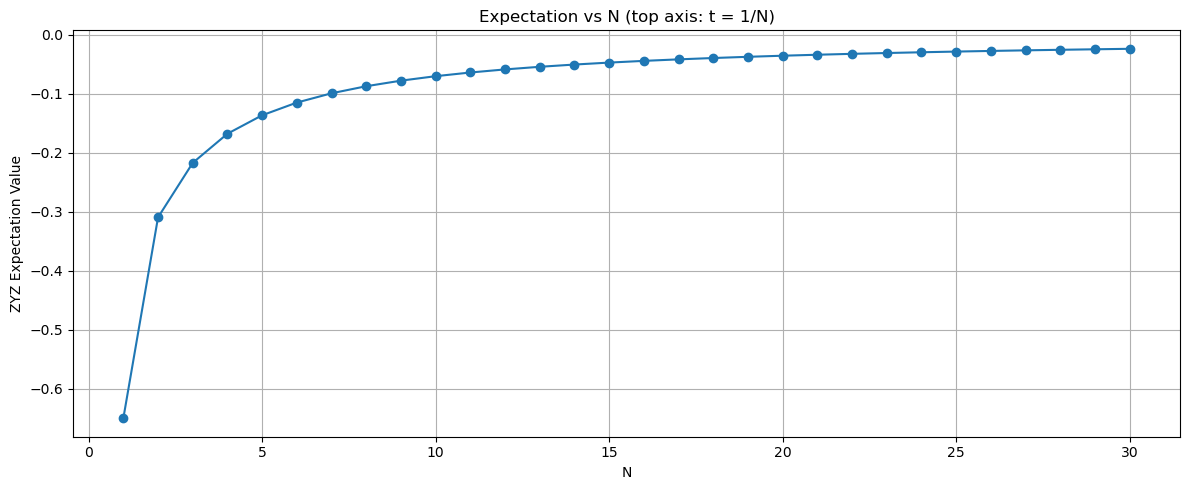

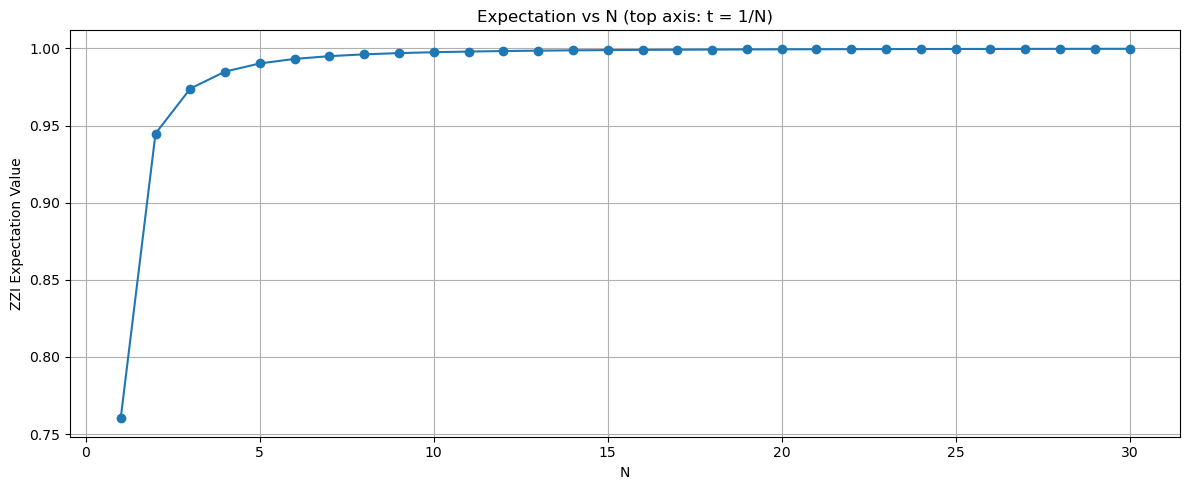

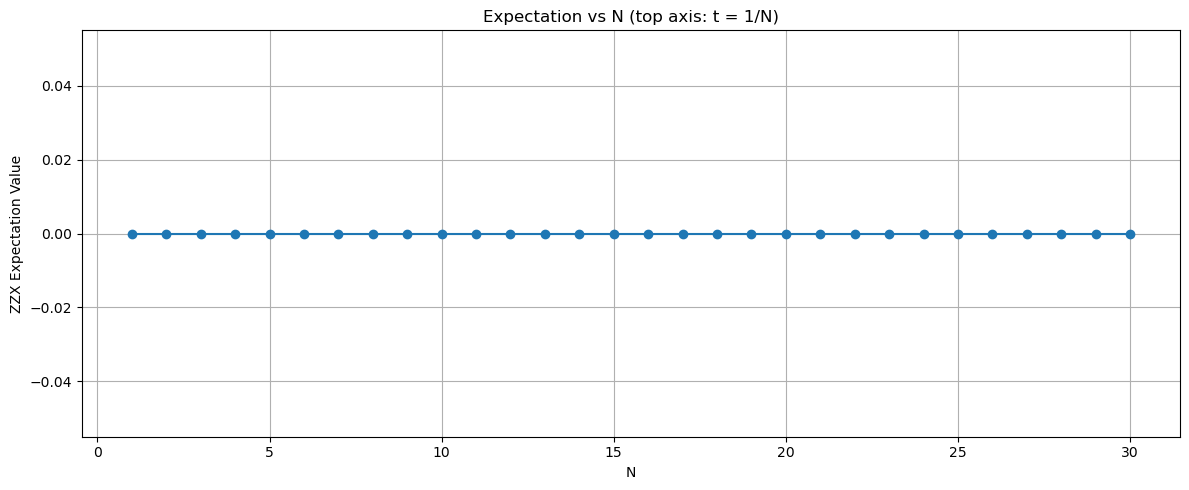

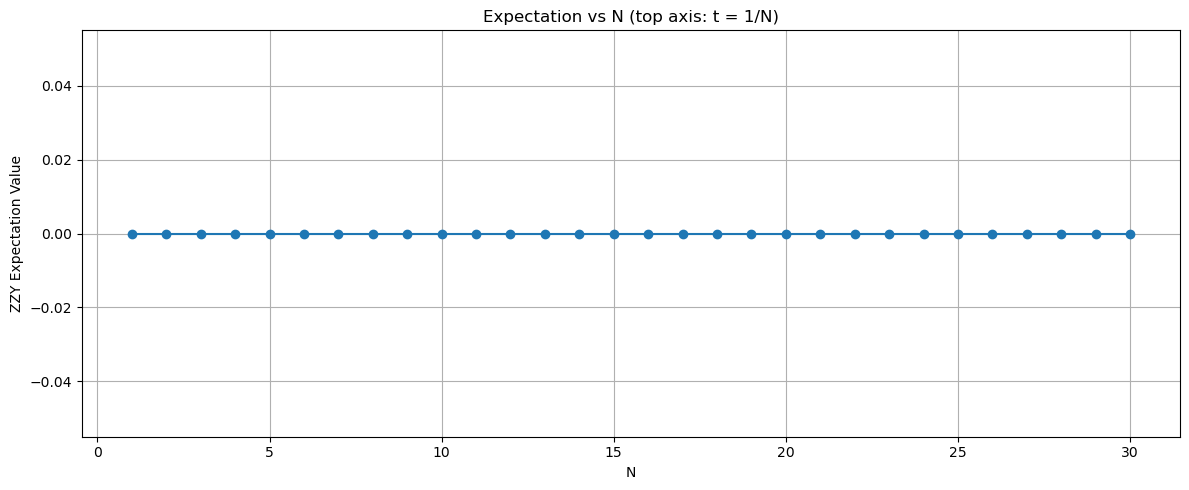

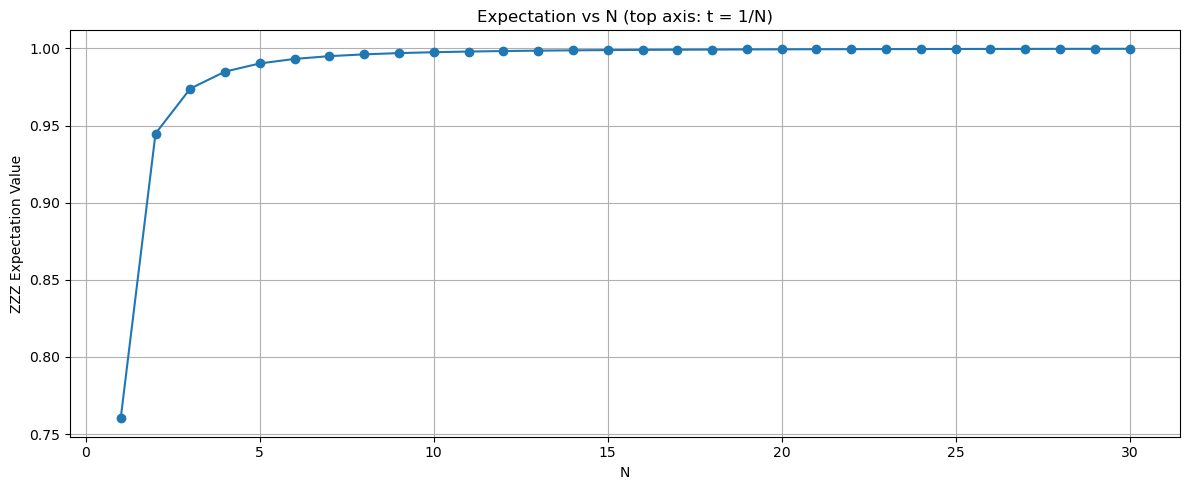

In [111]:
for observable in observables:
    exp_val_given_T_one_axis(N=30, observable=observable, save_fig=True)